# Real Estate Property Segmentation
### K-Means · Agglomerative (Hierarchical) · DBSCAN

**Goal:** group 500 property listings into market segments with similar characteristics (size, location, quality, price), using three clustering algorithms, tune each one, and compare them.

**What you will learn**
1. How to explore a dataset before clustering (distributions, correlations, pair plots).
2. When you **do** and **do not** need transformations like log-scaling – and why scaling is always needed.
3. How to choose *k* for K-Means with four different metrics.
4. How hierarchical clustering builds a dendrogram and how linkage choice changes the result.
5. How to tune DBSCAN's `eps` and `min_samples` with a k-distance plot and a grid search.
6. How to compare algorithms without ground-truth labels, and turn clusters into **market segments**.

> 💡 **Clustering is unsupervised learning** – there is no "correct answer" column. We judge clusters using internal metrics and by whether they make real-world sense.

# 1. Environment Setup & Data Loading

In [1]:
# --- Core data libraries ---
import pandas as pd
import numpy as np

# --- Visualisation ---
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401  (enables 3D plots)

# --- Preprocessing ---
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# --- Clustering algorithms ---
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors

# --- Evaluation metrics (no labels needed) ---
from sklearn.metrics import (silhouette_score, silhouette_samples,
                             davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score)

# --- Hierarchical clustering tools for the dendrogram ---
from scipy.cluster.hierarchy import linkage, dendrogram

import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 100

# Fixed colour order for clusters (colour-blind-checked palette):
# cluster 0 is always blue, 1 orange, 2 green ... in EVERY plot.
CLUSTER_COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100',
                  '#e87ba4', '#008300', '#6250d6', '#e34948']
NOISE_COLOR = '#b5b4ae'          # grey for DBSCAN noise (label -1)
MARKERS = ['o', 's', '^', 'D', 'v', 'P', 'X', '*']  # shape = a second cue besides colour

RANDOM_STATE = 42   # fix randomness so results are reproducible

In [2]:
# In Google Colab: first upload the file using the folder icon on the left (or files.upload()).
df = pd.read_csv('real_estate_clusters_500.csv')

print("Dataset shape:", df.shape)   # (rows, columns)
df.head()

Dataset shape: (500, 10)


,area_sqft,bedrooms,bathrooms,dist_to_city_center_km,dist_to_transit_m,school_rating,property_age_years,amenities_score,days_on_market,selling_price
0,2424,4,2.5,21.8,928,8.3,10,71,53,598800
1,822,1,1.5,5.8,76,6.0,11,56,11,247500
2,4249,5,3.5,3.7,391,9.6,3,97,61,1439400
3,571,1,1.5,6.2,233,4.9,10,38,19,206000
4,632,2,1.5,3.4,145,4.4,14,39,35,203700


### What do the columns mean?
| Column | Meaning |
|---|---|
| `area_sqft` | Floor area in square feet |
| `bedrooms`, `bathrooms` | Number of rooms (½ bathroom = toilet only) |
| `dist_to_city_center_km` | Distance to the city centre |
| `dist_to_transit_m` | Distance to the nearest public transport stop |
| `school_rating` | Rating of nearby schools (0–10) |
| `property_age_years` | Age of the building |
| `amenities_score` | Quality/number of nearby amenities (0–100) |
| `days_on_market` | How long the listing took to sell |
| `selling_price` | Final sale price |

In [3]:
# Data types and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   area_sqft               500 non-null    int64  
 1   bedrooms                500 non-null    int64  
 2   bathrooms               500 non-null    float64
 3   dist_to_city_center_km  500 non-null    float64
 4   dist_to_transit_m       500 non-null    int64  
 5   school_rating           500 non-null    float64
 6   property_age_years      500 non-null    int64  
 7   amenities_score         500 non-null    int64  
 8   days_on_market          500 non-null    int64  
 9   selling_price           500 non-null    int64  
dtypes: float64(3), int64(7)
memory usage: 39.2 KB


In [4]:
# Data-quality checks: missing values and duplicate rows
print("Missing values per column:\n", df.isna().sum(), sep='')
print("\nDuplicate rows:", df.duplicated().sum())

Missing values per column:
area_sqft                 0
bedrooms                  0
bathrooms                 0
dist_to_city_center_km    0
dist_to_transit_m         0
school_rating             0
property_age_years        0
amenities_score           0
days_on_market            0
selling_price             0
dtype: int64

Duplicate rows: 0


In [5]:
# Summary statistics. Note the very different SCALES:
# area is in the thousands, price in the hundreds of thousands, bedrooms are 1-6.
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
area_sqft,500.0,2229.49,1436.11,362.0,704.25,2157.00,3613.00,5337.0
bedrooms,500.0,3.22,1.40,1.0,2.00,3.00,4.00,6.0
bathrooms,500.0,2.43,1.18,1.0,1.50,2.50,3.50,5.0
dist_to_city_center_km,500.0,10.39,7.10,0.5,3.80,8.40,16.90,28.9
dist_to_transit_m,500.0,516.66,319.52,45.0,209.75,475.00,788.50,1387.0
school_rating,500.0,7.72,1.63,3.7,6.00,8.35,9.00,10.0
property_age_years,500.0,11.24,5.80,0.0,7.00,11.00,15.00,36.0
amenities_score,500.0,66.30,18.99,25.0,50.00,66.00,82.25,100.0
days_on_market,500.0,39.10,18.21,6.0,24.75,35.00,50.25,89.0
selling_price,500.0,674707.60,463924.51,142400.0,250650.00,564950.00,1144350.00,1782100.0


# 2. Exploratory Data Analysis (EDA)
Clustering relies on distances, so we need to understand each feature's distribution and how features relate.

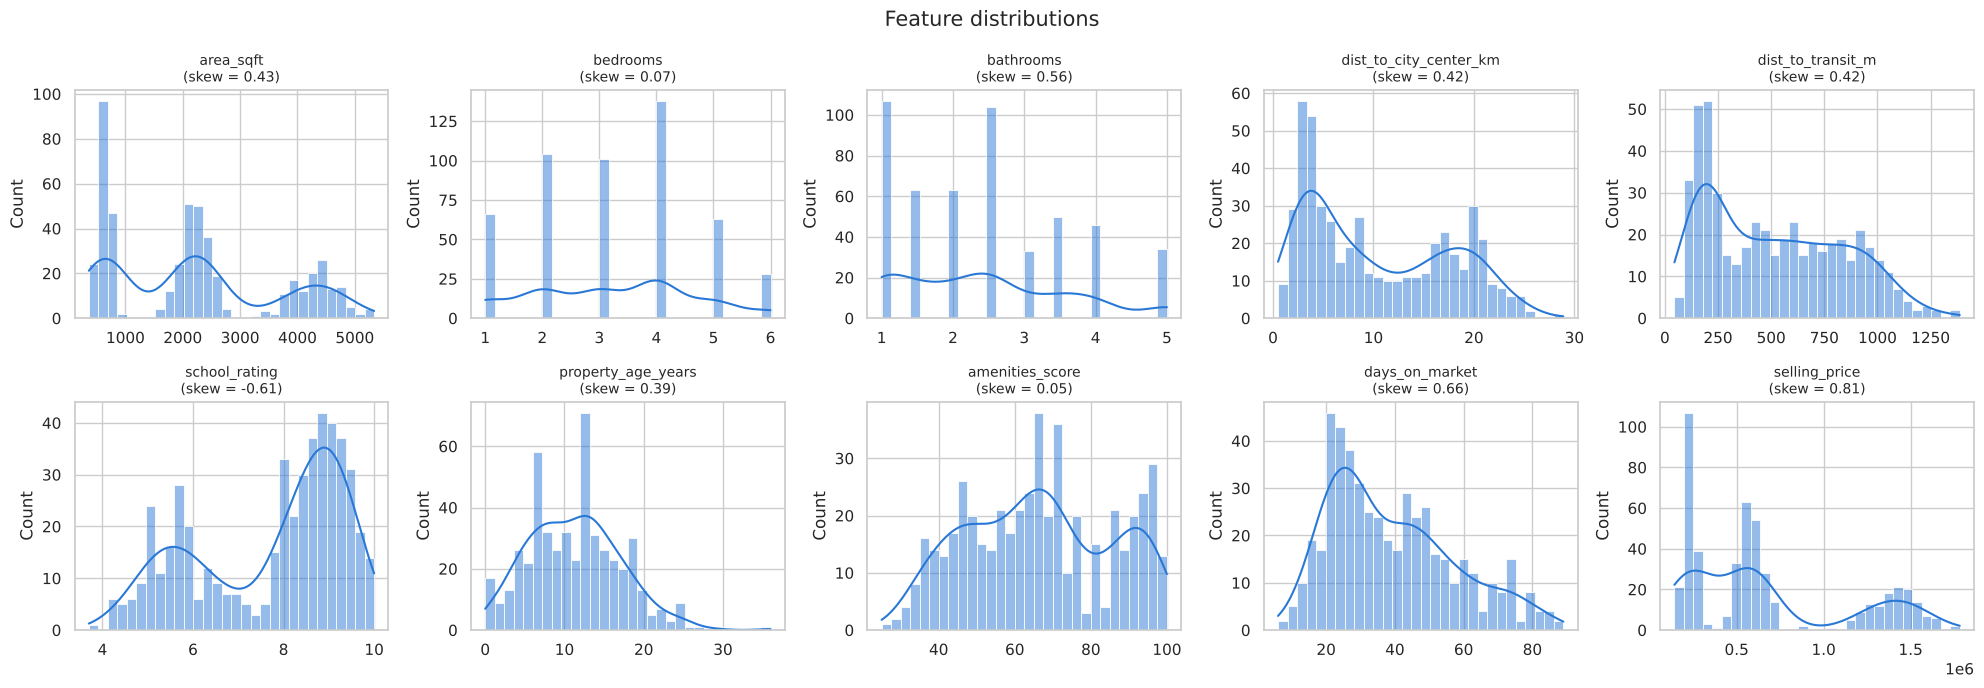

In [6]:
# Histograms of every feature, with skewness in the title
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for ax, col in zip(axes.flat, df.columns):
    sns.histplot(df[col], bins=30, ax=ax, color=CLUSTER_COLORS[0], kde=True)
    ax.set_title(f"{col}\n(skew = {df[col].skew():.2f})", fontsize=10)
    ax.set_xlabel('')
plt.suptitle('Feature distributions', fontsize=15)
plt.tight_layout(); plt.show()

**Observation:** many histograms have **two or three humps** (they are *multimodal*) – e.g. `area_sqft`, `selling_price`, `dist_to_city_center_km`. Multiple humps are a strong hint that the data contains **distinct groups**. That is exactly what clustering looks for.

Also note: all skewness values are **below 1**, so there are no extreme long tails.

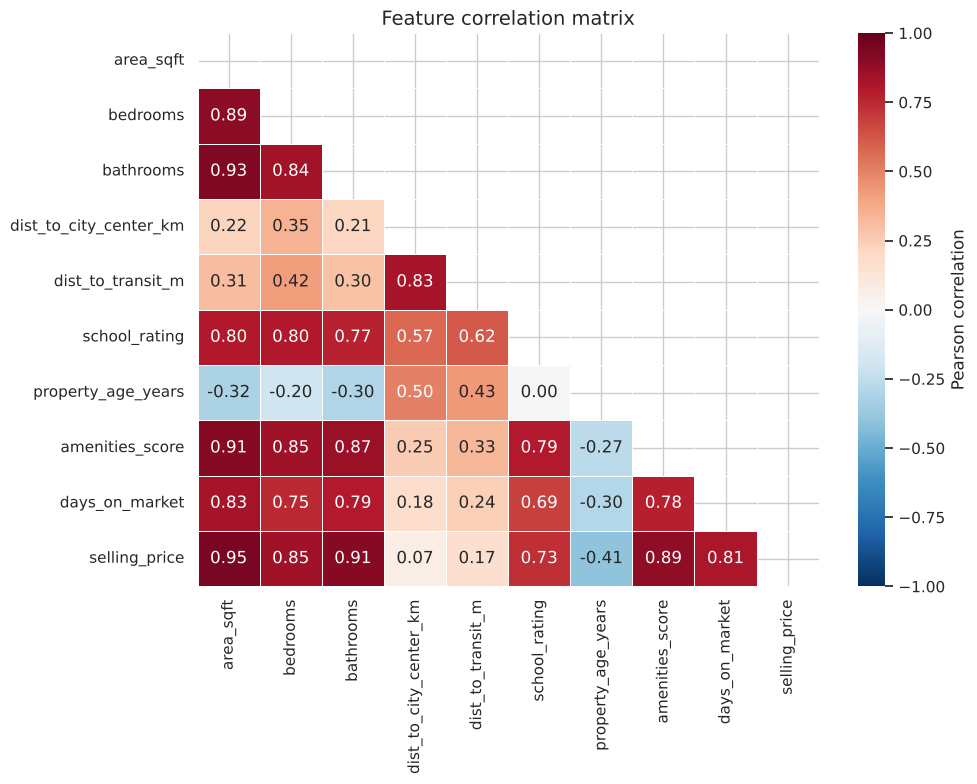

In [7]:
# Correlation heatmap
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))   # hide the mirrored upper half

plt.figure(figsize=(10, 8))
sns.heatmap(corr, mask=mask, cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            annot=True, fmt='.2f', linewidths=0.5, cbar_kws={'label': 'Pearson correlation'})
plt.title('Feature correlation matrix', fontsize=14)
plt.tight_layout(); plt.show()

**Observation:** size-related features (`area_sqft`, `bedrooms`, `bathrooms`, `selling_price`, `amenities_score`) are strongly correlated with each other. Correlated features "vote together" in distance calculations, giving the size/value dimension more weight. That's acceptable here because it reflects a real difference between property types, but it's worth knowing.

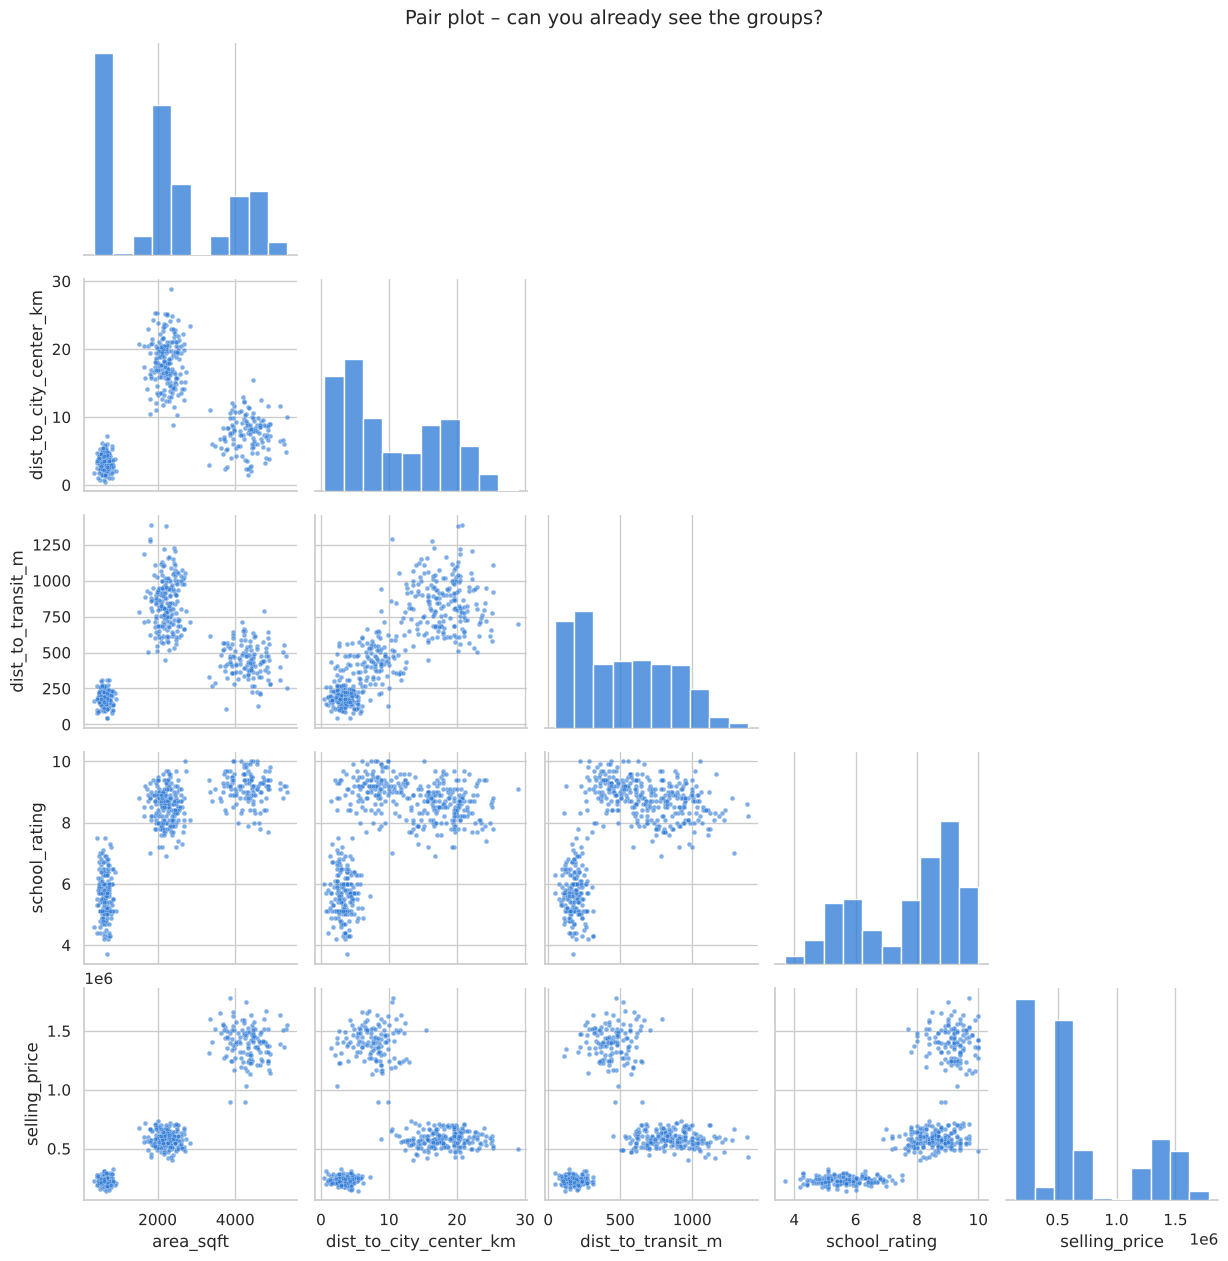

In [8]:
# Pair plot of a few key features. With only 500 rows we can plot every point.
# Look for visible "clouds" – each cloud is a candidate cluster.
key = ['area_sqft', 'dist_to_city_center_km', 'dist_to_transit_m', 'school_rating', 'selling_price']
g = sns.pairplot(df[key], corner=True, plot_kws=dict(s=12, alpha=0.6, color=CLUSTER_COLORS[0]),
                 diag_kws=dict(color=CLUSTER_COLORS[0]))
g.fig.suptitle('Pair plot – can you already see the groups?', y=1.01, fontsize=14)
plt.show()

You can already see **about three clouds** in several panels (e.g. `area_sqft` vs `dist_to_city_center_km`). Our job now is to let the algorithms find them formally and check whether they agree.

# 3. Preprocessing
Decisions for this dataset:
1. **Missing values / duplicates:** none found → nothing to impute or drop.
2. **ID column:** none → every column is a feature.
3. **Log transform?** Only needed for heavily skewed features (|skew| > ~1–2). All features here have |skew| < 1, so we **skip it**. *Don't apply transformations blindly – check first.*
4. **Scaling – always needed.** Without scaling, `selling_price` (hundreds of thousands) would completely dominate `bedrooms` (1–6) in any distance calculation.

In [9]:
# Check skewness programmatically - same rule as before: transform only if |skew| > 1
skew = df.skew()
needs_log = skew[skew.abs() > 1].index.tolist()
print("Features needing a log transform:", needs_log if needs_log else "none")

Features needing a log transform: none


Values with |z| > 3 per feature:
area_sqft                 0
bedrooms                  0
bathrooms                 0
dist_to_city_center_km    0
dist_to_transit_m         0
school_rating             0
property_age_years        2
amenities_score           0
days_on_market            0
selling_price             0
dtype: int64


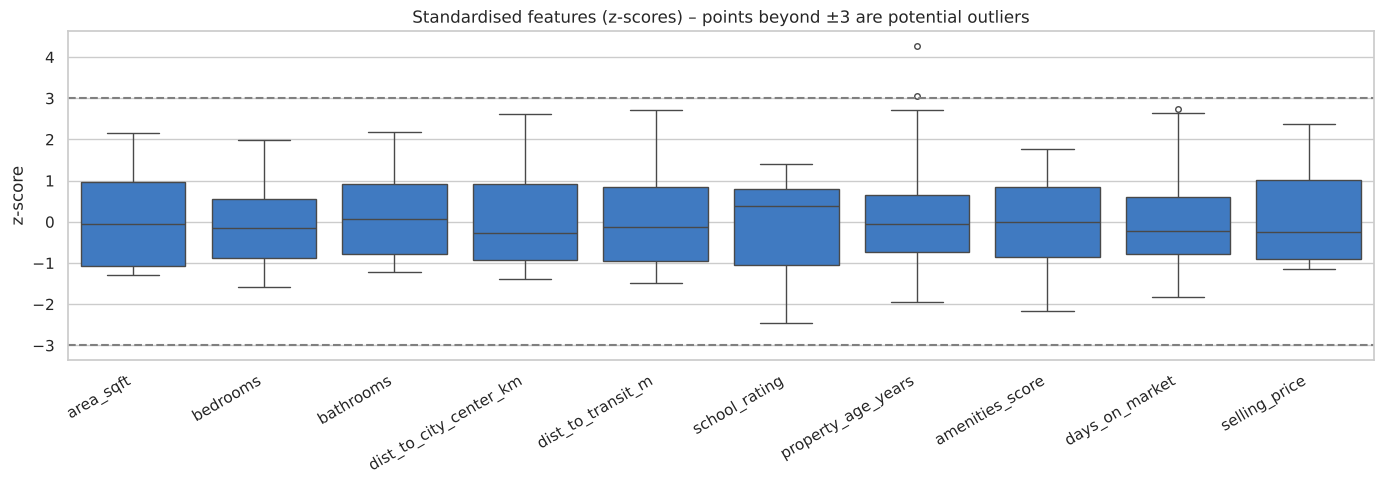

In [10]:
# Outlier check: how many values lie more than 3 standard deviations from the mean?
z = (df - df.mean()) / df.std()
print("Values with |z| > 3 per feature:")
print((z.abs() > 3).sum())

plt.figure(figsize=(14, 5))
sns.boxplot(data=z, color=CLUSTER_COLORS[0], fliersize=4)
plt.axhline(3, ls='--', color='grey'); plt.axhline(-3, ls='--', color='grey')
plt.title('Standardised features (z-scores) – points beyond ±3 are potential outliers')
plt.xticks(rotation=30, ha='right'); plt.ylabel('z-score')
plt.tight_layout(); plt.show()

Only a couple of mild outliers (e.g. one very old property). They are realistic values, so we keep them – DBSCAN will tell us later whether they look unusual.

In [11]:
X = df.copy()                 # all 10 columns are features
X_original = X.copy()         # untouched copy in real units, used for interpretation later

# Standardise: every column -> mean 0, standard deviation 1
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled shape:", X_scaled.shape)
print("Means ≈ 0:", X_scaled.mean(axis=0).round(3))
print("Stds  ≈ 1:", X_scaled.std(axis=0).round(3))

Scaled shape: (500, 10)
Means ≈ 0: [ 0. -0. -0. -0.  0. -0. -0.  0.  0.  0.]
Stds  ≈ 1: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


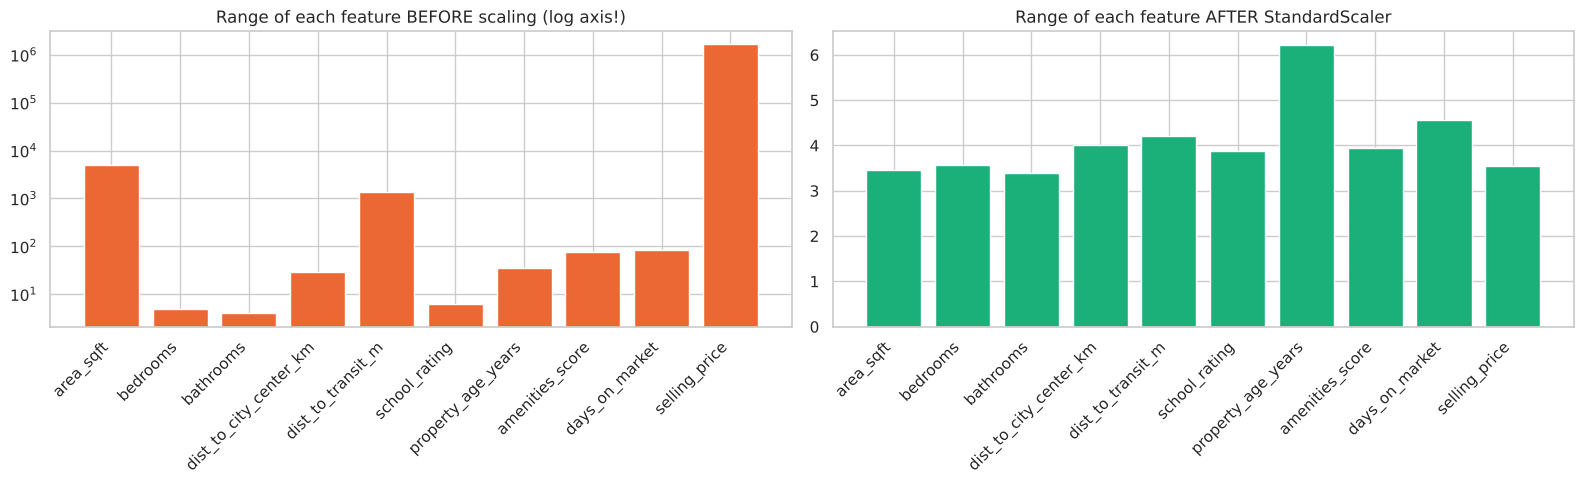

In [12]:
# Visual proof of why scaling matters: raw ranges vs scaled ranges
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].bar(X.columns, X.max() - X.min(), color=CLUSTER_COLORS[1])
axes[0].set_yscale('log'); axes[0].set_title('Range of each feature BEFORE scaling (log axis!)')
axes[0].tick_params(axis='x', rotation=45)
scaled_df = pd.DataFrame(X_scaled, columns=X.columns)
axes[1].bar(X.columns, scaled_df.max() - scaled_df.min(), color=CLUSTER_COLORS[2])
axes[1].set_title('Range of each feature AFTER StandardScaler')
axes[1].tick_params(axis='x', rotation=45)
for ax in axes:
    plt.setp(ax.get_xticklabels(), ha='right')
plt.tight_layout(); plt.show()

# 4. PCA for Visualisation
We have 10 dimensions – too many to plot. **PCA** finds new axes that keep as much variance as possible, so we can draw the clusters in 2D/3D.

⚠️ All three algorithms are trained on the **full 10-D scaled data**. PCA is only used for the pictures.

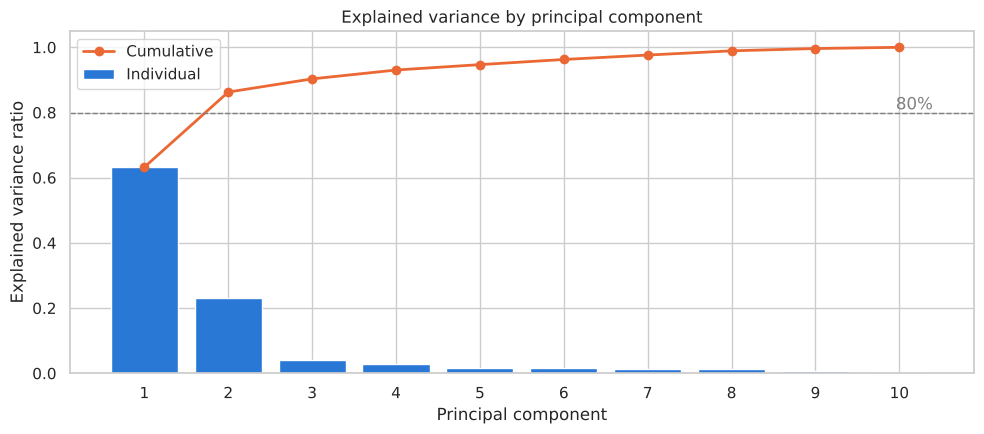

PC1+PC2 explain 86.3% of the variance; PC1-3 explain 90.3%


In [13]:
pca_full = PCA(random_state=RANDOM_STATE).fit(X_scaled)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)

fig, ax = plt.subplots(figsize=(10, 4.5))
comps = np.arange(1, len(cum_var) + 1)
ax.bar(comps, pca_full.explained_variance_ratio_, color=CLUSTER_COLORS[0], label='Individual')
ax.plot(comps, cum_var, marker='o', color=CLUSTER_COLORS[1], lw=2, label='Cumulative')
ax.axhline(0.80, ls='--', color='grey', lw=1)
ax.text(len(cum_var) + 0.4, 0.81, '80%', ha='right', color='grey')
ax.set_xlabel('Principal component'); ax.set_ylabel('Explained variance ratio')
ax.set_title('Explained variance by principal component')
ax.set_xticks(comps); ax.legend()
plt.tight_layout(); plt.show()

print(f"PC1+PC2 explain {cum_var[1]:.1%} of the variance; PC1-3 explain {cum_var[2]:.1%}")

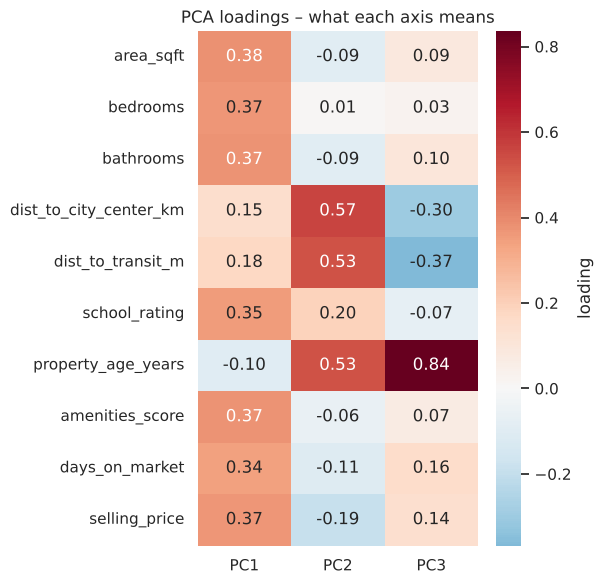

In [14]:
pca3 = PCA(n_components=3, random_state=RANDOM_STATE)
X_pca = pca3.fit_transform(X_scaled)

# Loadings: how strongly each original feature contributes to each component
loadings = pd.DataFrame(pca3.components_.T, index=X.columns, columns=['PC1', 'PC2', 'PC3'])
plt.figure(figsize=(6, 6))
sns.heatmap(loadings, cmap='RdBu_r', center=0, annot=True, fmt='.2f', cbar_kws={'label': 'loading'})
plt.title('PCA loadings – what each axis means')
plt.tight_layout(); plt.show()

**Reading the loadings:** PC1 is driven mostly by size and value (area, bedrooms, bathrooms, price, amenities) → a "**property size/value**" axis. PC2 is driven mostly by location (distance to city centre and to transit) → an "**urban vs suburban**" axis. PC1 and PC2 together keep about 86% of the information, so the 2D plots below are a faithful picture.

In [15]:
# ---------- Helper functions reused for every algorithm ----------

def plot_clusters_2d(labels, title, ax=None, centers_pca=None):
    # PC1 vs PC2 scatter coloured by cluster; DBSCAN noise (-1) drawn as grey crosses.
    if ax is None:
        fig, ax = plt.subplots(figsize=(9, 7))
    for lab in sorted(set(labels)):
        m = labels == lab
        if lab == -1:
            ax.scatter(X_pca[m, 0], X_pca[m, 1], s=40, c='black', marker='x',
                       label=f'Noise ({m.sum()})')
        else:
            ax.scatter(X_pca[m, 0], X_pca[m, 1], s=28, alpha=0.7,
                       c=CLUSTER_COLORS[lab % 8], marker=MARKERS[lab % 8],
                       edgecolors='white', linewidths=0.4, label=f'Cluster {lab} ({m.sum()})')
    if centers_pca is not None:
        ax.scatter(centers_pca[:, 0], centers_pca[:, 1], s=300, c='black', marker='*',
                   edgecolors='white', linewidths=1.5, label='Centroids')
    ax.set_xlabel('PC1 (size / value)'); ax.set_ylabel('PC2 (location)'); ax.set_title(title)
    leg = ax.legend(fontsize=8, loc='best')
    if centers_pca is not None:
        leg.legend_handles[-1].set_sizes([90])
    return ax


def plot_silhouette(X_data, labels, title, ax=None):
    # One horizontal bar per property, grouped by cluster.
    # Long bars to the right = well clustered; bars left of 0 = probably in the wrong cluster.
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 6))
    sil_vals = silhouette_samples(X_data, labels)
    avg = sil_vals.mean()
    y_low = 5
    for lab in sorted(set(labels)):
        vals = np.sort(sil_vals[labels == lab])
        y_up = y_low + len(vals)
        ax.fill_betweenx(np.arange(y_low, y_up), 0, vals, color=CLUSTER_COLORS[lab % 8], alpha=0.85)
        ax.text(-0.08, y_low + len(vals) / 2, str(lab), fontsize=10)
        y_low = y_up + 5
    ax.axvline(avg, color='black', ls='--', lw=1.2)
    ax.text(avg + 0.01, y_low * 0.97, f'mean = {avg:.3f}', fontsize=9)
    ax.set_xlabel('Silhouette coefficient'); ax.set_ylabel('Cluster')
    ax.set_yticks([]); ax.set_xlim(-0.3, 1); ax.set_title(title)
    return ax


def plot_cluster_sizes(labels, title, ax=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 4))
    counts = pd.Series(labels).value_counts().sort_index()
    colors = [NOISE_COLOR if l == -1 else CLUSTER_COLORS[l % 8] for l in counts.index]
    names = ['Noise' if l == -1 else f'C{l}' for l in counts.index]
    bars = ax.bar(names, counts.values, color=colors)
    for b, v in zip(bars, counts.values):
        ax.text(b.get_x() + b.get_width() / 2, v, f'{v}\n({v / len(labels):.0%})',
                ha='center', va='bottom', fontsize=9)
    ax.set_ylabel('Properties'); ax.set_title(title); ax.set_ylim(0, counts.max() * 1.2)
    return ax


def evaluate(X_data, labels, ignore_noise=True):
    # Silhouette, Davies-Bouldin and Calinski-Harabasz. Noise (-1) is excluded for DBSCAN.
    labels = np.asarray(labels)
    if ignore_noise:
        keep = labels != -1
        X_data, labels = X_data[keep], labels[keep]
    if len(set(labels)) < 2:
        return dict(silhouette=np.nan, davies_bouldin=np.nan, calinski_harabasz=np.nan)
    return dict(silhouette=silhouette_score(X_data, labels),
                davies_bouldin=davies_bouldin_score(X_data, labels),
                calinski_harabasz=calinski_harabasz_score(X_data, labels))

### 📏 The three evaluation metrics
| Metric | Range | Better | Intuition |
|---|---|---|---|
| **Silhouette** | −1 … 1 | **higher** | How close a point is to its own cluster vs. the nearest other cluster |
| **Davies–Bouldin (DB)** | 0 … ∞ | **lower** | How similar each cluster is to its most similar neighbour |
| **Calinski–Harabasz (CH)** | 0 … ∞ | **higher** | Between-cluster spread ÷ within-cluster spread |

Rough guide for silhouette: **> 0.5 = strong structure**, 0.25–0.5 = reasonable, < 0.25 = weak/overlapping.

# 5. K-Means Clustering
**How it works:** choose *k* centroids → assign each point to the nearest centroid → move each centroid to the mean of its points → repeat until nothing changes.

**Main hyperparameter:** `n_clusters` (*k*). We'll test *k* = 2 … 10.

In [16]:
k_range = range(2, 11)
km_results = []

for k in k_range:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=RANDOM_STATE)
    labels = km.fit_predict(X_scaled)
    scores = evaluate(X_scaled, labels, ignore_noise=False)
    scores.update(k=k, inertia=km.inertia_,      # inertia = within-cluster sum of squared distances
                  smallest_cluster=np.bincount(labels).min() / len(labels))
    km_results.append(scores)

km_results = pd.DataFrame(km_results).set_index('k')
km_results.round(3)

,silhouette,davies_bouldin,calinski_harabasz,inertia,smallest_cluster
k,,,,,
2,0.511,0.719,570.214,2330.993,0.340
3,0.616,0.603,1178.141,870.927,0.260
4,0.450,1.210,890.352,783.062,0.170
5,0.287,1.535,720.283,733.087,0.168
6,0.184,1.825,624.364,683.109,0.128
7,0.165,1.944,549.888,649.997,0.102
8,0.162,1.861,493.197,623.672,0.050
9,0.159,1.832,447.584,602.946,0.050
10,0.125,1.923,408.823,587.613,0.066


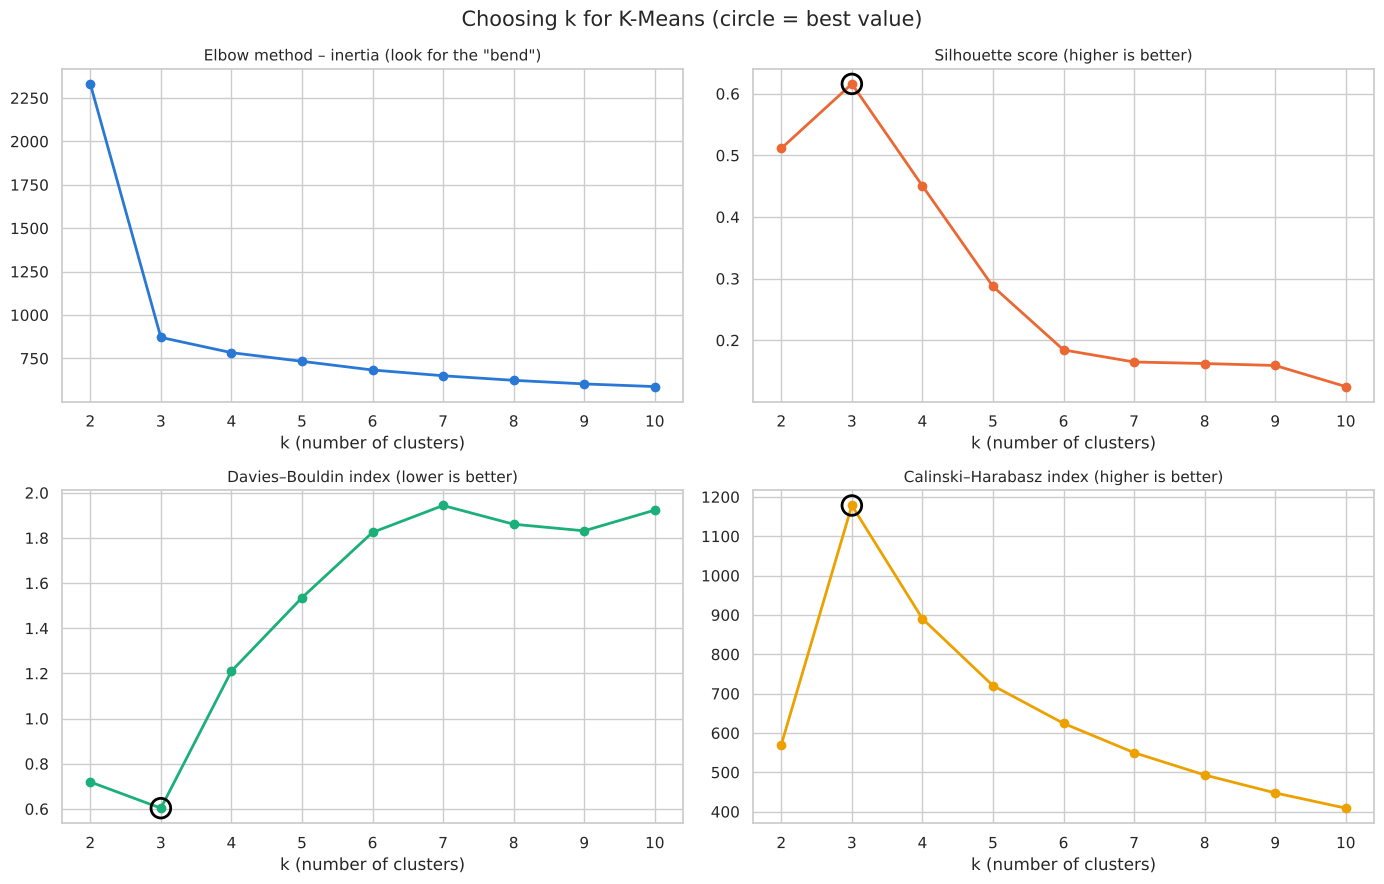

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
ks = km_results.index
panels = [('inertia', 'Elbow method – inertia (look for the "bend")', 0),
          ('silhouette', 'Silhouette score (higher is better)', 1),
          ('davies_bouldin', 'Davies–Bouldin index (lower is better)', 2),
          ('calinski_harabasz', 'Calinski–Harabasz index (higher is better)', 3)]

for ax, (col, title, c) in zip(axes.flat, panels):
    ax.plot(ks, km_results[col], marker='o', lw=2, color=CLUSTER_COLORS[c])
    # mark the best k for this metric
    best = km_results[col].idxmin() if col in ('inertia', 'davies_bouldin') else km_results[col].idxmax()
    if col != 'inertia':
        ax.scatter([best], [km_results.loc[best, col]], s=200, facecolors='none',
                   edgecolors='black', linewidths=2, zorder=5)
    ax.set_title(title, fontsize=11); ax.set_xlabel('k (number of clusters)'); ax.set_xticks(list(ks))

plt.suptitle('Choosing k for K-Means (circle = best value)', fontsize=15)
plt.tight_layout(); plt.show()

### Choosing *k*
Unlike many real datasets, here **all four methods agree**:
* The **elbow** is sharp at *k* = 3 – adding a 4th cluster barely reduces inertia.
* **Silhouette** peaks at *k* = 3 (> 0.6 = strong structure).
* **Davies–Bouldin** is lowest and **Calinski–Harabasz** is highest at *k* = 3.

When independent metrics agree this clearly, you can be confident there are **3 natural groups**.

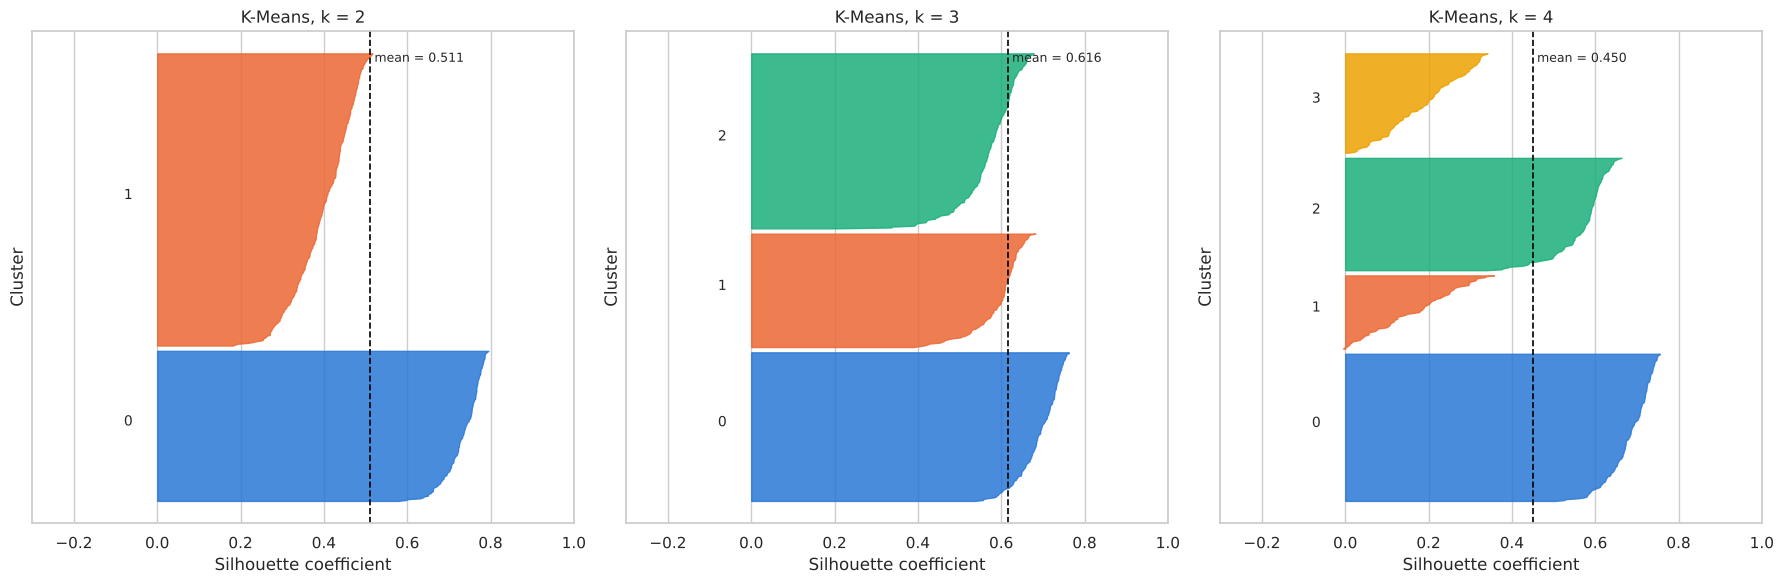

In [18]:
# Silhouette plots for k = 2, 3, 4 side by side.
# Good clustering = all "knives" thick, similar height above the mean line, few negative values.
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, k in zip(axes, [2, 3, 4]):
    lab = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_scaled)
    plot_silhouette(X_scaled, lab, f'K-Means, k = {k}', ax=ax)
plt.tight_layout(); plt.show()

* **k = 2:** one cluster is a mixture of two groups (its knife is uneven).
* **k = 3:** three thick, even knives – the best fit.
* **k = 4:** a natural group is split in two, and the two halves get low silhouette values because they sit right next to each other.

In [19]:
# Pick k automatically: the k with the highest silhouette score
BEST_K = int(km_results['silhouette'].idxmax())

# Final tuned K-Means:
#  init='k-means++' -> smart, spread-out starting centroids
#  n_init=50        -> 50 restarts, keep the best (lowest inertia)
#  max_iter=500     -> plenty of iterations to converge
kmeans = KMeans(n_clusters=BEST_K, init='k-means++', n_init=50, max_iter=500,
                random_state=RANDOM_STATE)
kmeans_labels = kmeans.fit_predict(X_scaled)

km_scores = evaluate(X_scaled, kmeans_labels, ignore_noise=False)
print(f"Tuned K-Means (k={BEST_K})")
for name, v in km_scores.items():
    print(f"  {name:<18}: {v:.4f}")

Tuned K-Means (k=3)
  silhouette        : 0.6159
  davies_bouldin    : 0.6033
  calinski_harabasz : 1178.1407


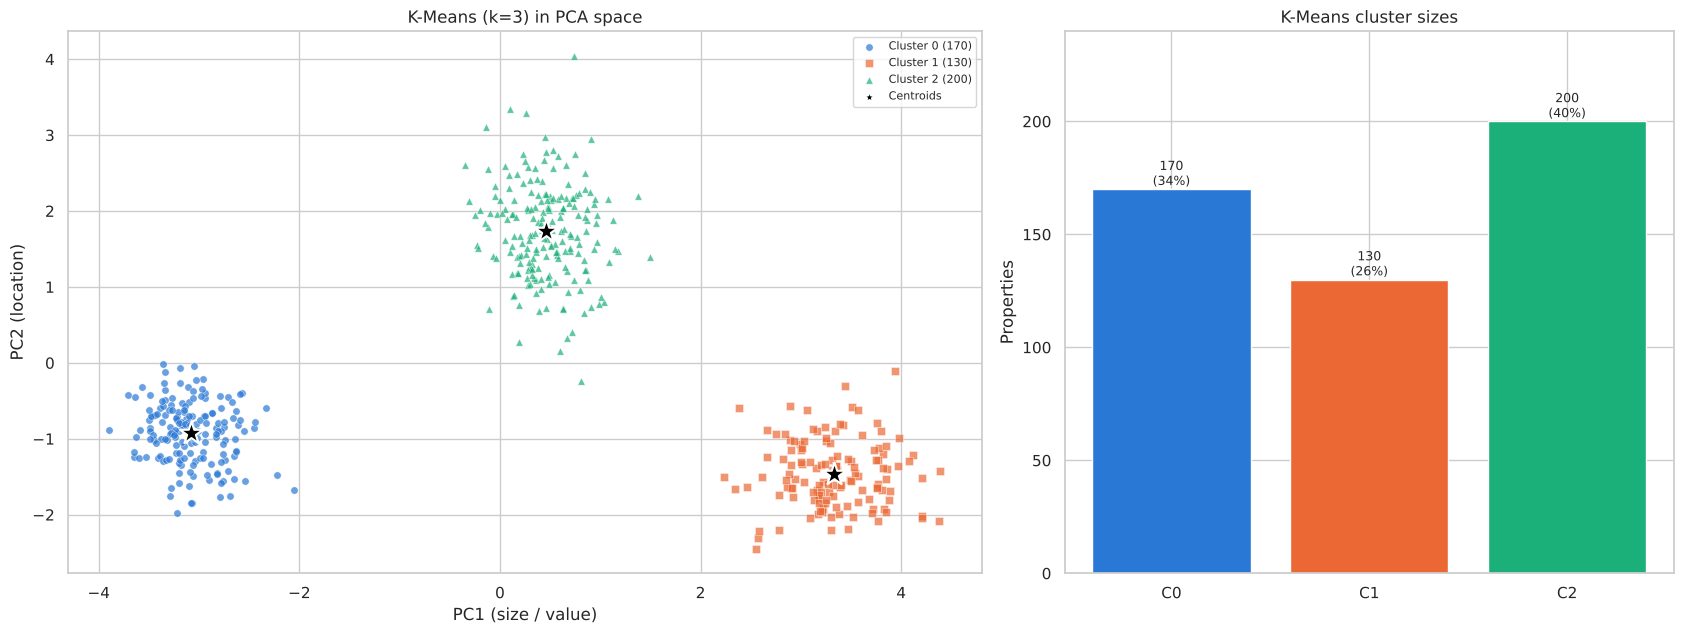

In [20]:
centers_pca = pca3.transform(kmeans.cluster_centers_)   # put the centroids in PCA space too

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={'width_ratios': [1.5, 1]})
plot_clusters_2d(kmeans_labels, f'K-Means (k={BEST_K}) in PCA space', ax=axes[0], centers_pca=centers_pca)
plot_cluster_sizes(kmeans_labels, 'K-Means cluster sizes', ax=axes[1])
plt.tight_layout(); plt.show()

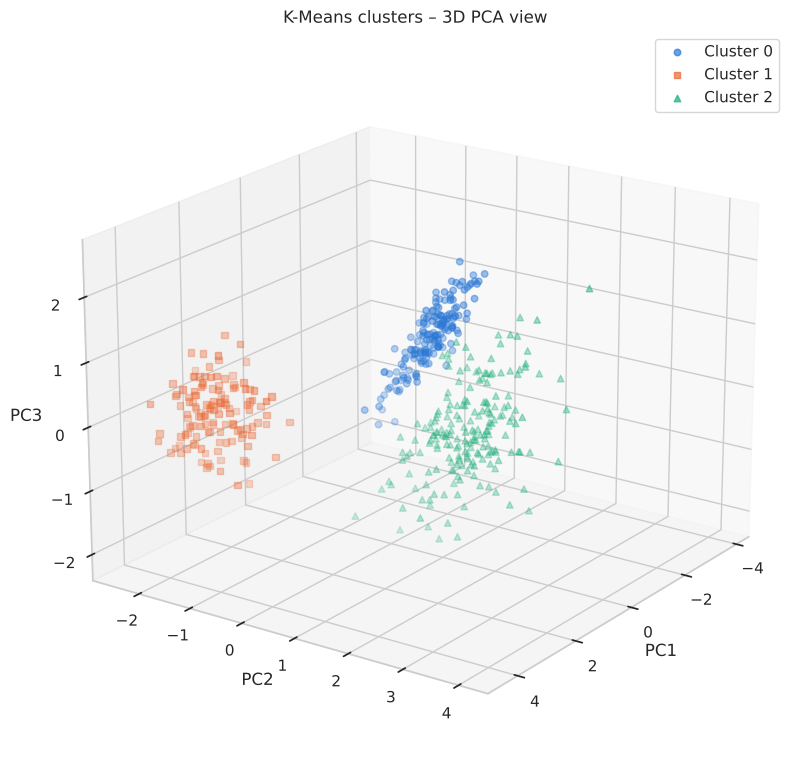

In [21]:
# 3D view (PC1, PC2, PC3)
fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection='3d')
for lab in range(BEST_K):
    m = kmeans_labels == lab
    ax.scatter(X_pca[m, 0], X_pca[m, 1], X_pca[m, 2], s=22, alpha=0.7,
               c=CLUSTER_COLORS[lab], marker=MARKERS[lab], label=f'Cluster {lab}')
ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.set_zlabel('PC3')
ax.set_title('K-Means clusters – 3D PCA view'); ax.view_init(elev=20, azim=35)
ax.legend(); plt.tight_layout(); plt.show()

# 6. Agglomerative (Hierarchical) Clustering
**How it works (bottom-up):** every property starts as its own cluster → the two **closest** clusters are merged → repeat until *k* clusters remain.

"Closest" depends on the **linkage**:
| Linkage | Distance between two clusters = | Typical behaviour |
|---|---|---|
| `ward` | increase in within-cluster variance after merging | compact, similar-sized clusters |
| `complete` | distance between the **farthest** pair of points | compact, sensitive to outliers |
| `average` | **average** distance over all pairs | in-between |
| `single` | distance between the **closest** pair of points | "chaining"; isolates outliers |

Hyperparameters to tune: **linkage** and **n_clusters**.

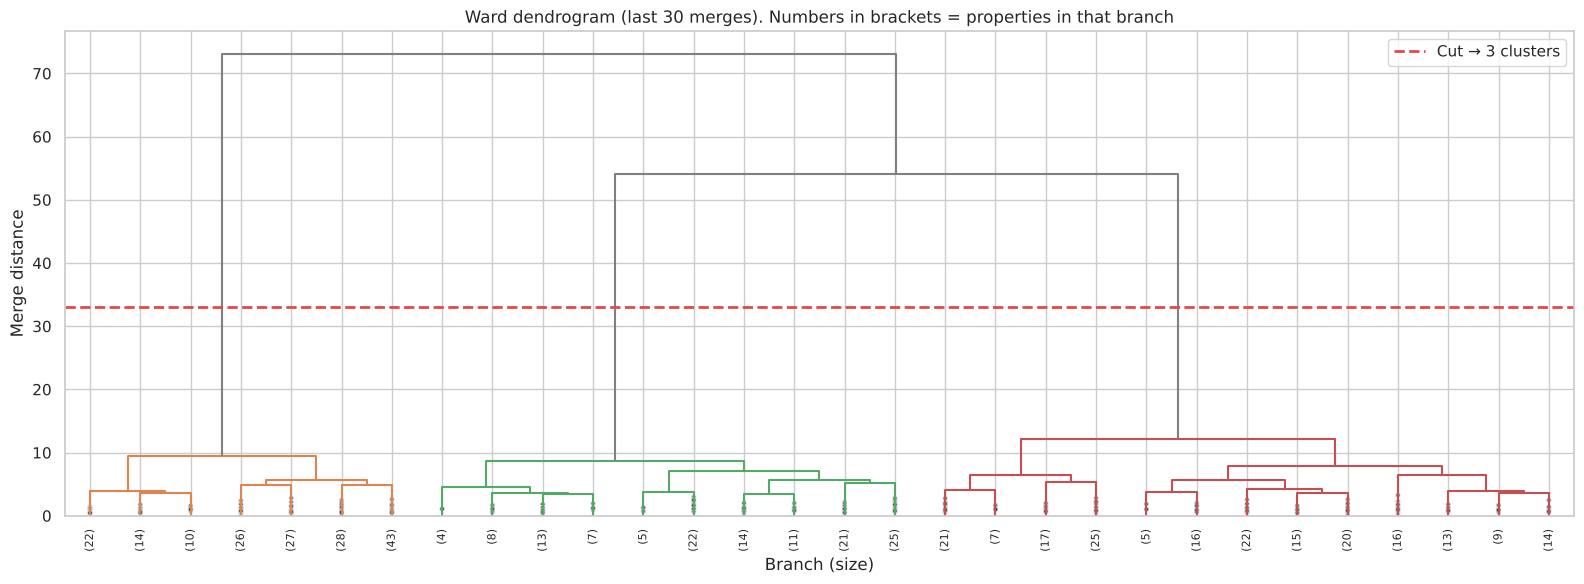

In [22]:
# Ward dendrogram. With 500 points we can afford the full tree (shown truncated for readability).
Z_ward = linkage(X_scaled, method='ward')

plt.figure(figsize=(16, 6))
dendrogram(Z_ward, truncate_mode='lastp', p=30, leaf_rotation=90, leaf_font_size=8,
           show_contracted=True, color_threshold=(Z_ward[-3, 2] + Z_ward[-2, 2]) / 2,
           above_threshold_color='grey')
cut = (Z_ward[-3, 2] + Z_ward[-2, 2]) / 2      # height between the last two merges -> 3 clusters
plt.axhline(cut, color=CLUSTER_COLORS[7], ls='--', lw=2, label='Cut → 3 clusters')
plt.title('Ward dendrogram (last 30 merges). Numbers in brackets = properties in that branch')
plt.xlabel('Branch (size)'); plt.ylabel('Merge distance')
plt.legend(); plt.tight_layout(); plt.show()

**Reading the dendrogram:** the three coloured branches join only at a **very large height** – much taller than any merge inside a branch. A big vertical gap like this is the dendrogram's way of saying "these groups are genuinely different". Cutting anywhere in that gap gives 3 clusters.

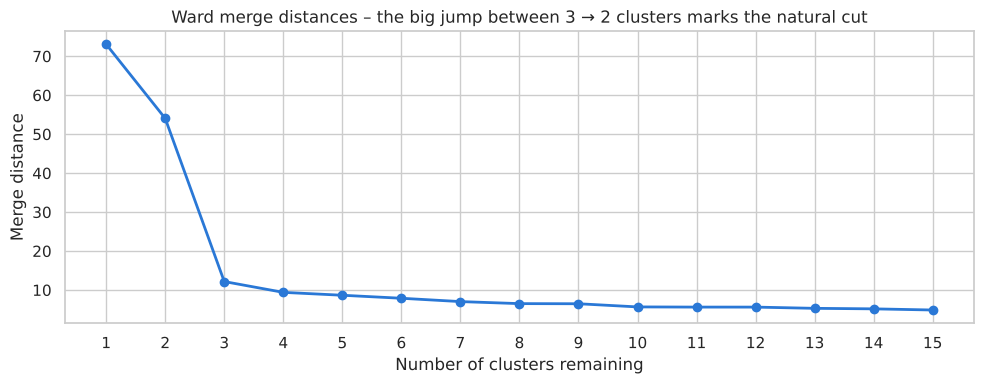

In [23]:
# Merge-distance plot: the height of the last 15 merges.
# A big jump = merging two clusters that should have stayed separate.
last = Z_ward[-15:, 2][::-1]
plt.figure(figsize=(10, 4))
plt.plot(range(1, len(last) + 1), last, marker='o', lw=2, color=CLUSTER_COLORS[0])
plt.xticks(range(1, len(last) + 1))
plt.xlabel('Number of clusters remaining'); plt.ylabel('Merge distance')
plt.title('Ward merge distances – the big jump between 3 → 2 clusters marks the natural cut')
plt.tight_layout(); plt.show()

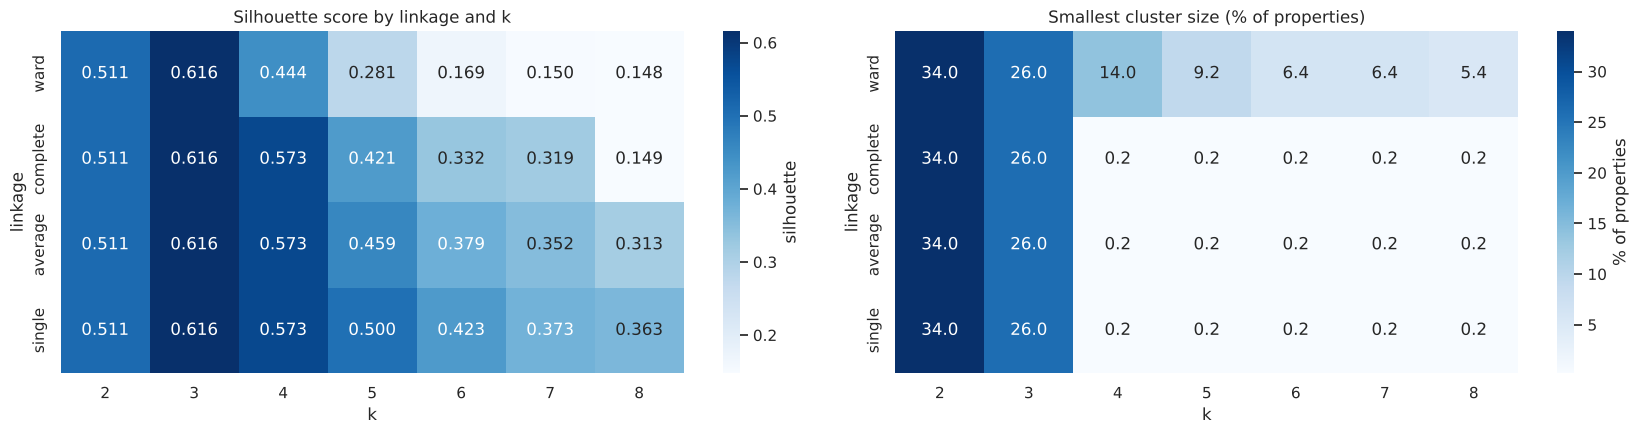

In [24]:
# Grid search: linkage x number of clusters
linkages = ['ward', 'complete', 'average', 'single']
agg_results = []
for link in linkages:
    for k in range(2, 9):
        labels = AgglomerativeClustering(n_clusters=k, linkage=link).fit_predict(X_scaled)
        s = evaluate(X_scaled, labels, ignore_noise=False)
        s.update(linkage=link, k=k, smallest_cluster=np.bincount(labels).min() / len(labels))
        agg_results.append(s)
agg_results = pd.DataFrame(agg_results)

sil_pivot = agg_results.pivot(index='linkage', columns='k', values='silhouette').loc[linkages]
small_pivot = agg_results.pivot(index='linkage', columns='k', values='smallest_cluster').loc[linkages]

fig, axes = plt.subplots(1, 2, figsize=(17, 4.5))
sns.heatmap(sil_pivot, annot=True, fmt='.3f', cmap='Blues', ax=axes[0], cbar_kws={'label': 'silhouette'})
axes[0].set_title('Silhouette score by linkage and k')
sns.heatmap(small_pivot * 100, annot=True, fmt='.1f', cmap='Blues', ax=axes[1],
            cbar_kws={'label': '% of properties'})
axes[1].set_title('Smallest cluster size (% of properties)')
plt.tight_layout(); plt.show()

**What the heatmaps show:**
* At *k* = 2 and *k* = 3, **all four linkages give exactly the same score** – when groups are well separated, it doesn't matter how you measure the distance between clusters.
* For *k* ≥ 4, `single` and `average` linkage keep higher silhouettes, but look at the right-hand heatmap: they do it by splitting off **tiny clusters of 1–2 properties** (outliers), not real segments. Always check cluster sizes!

**Rule:** accept only solutions where every cluster has ≥ 5% of the properties, then pick the best silhouette.

In [25]:
MIN_CLUSTER_FRAC = 0.05
valid = agg_results[agg_results['smallest_cluster'] >= MIN_CLUSTER_FRAC]
display(valid.sort_values(['silhouette', 'linkage'], ascending=[False, False]).head(6).round(3))

best_agg = valid.sort_values(['silhouette', 'linkage'], ascending=[False, False]).iloc[0]
# Ties are common here; we prefer Ward among equal scores (ascending=False puts 'ward' first)
AGG_LINKAGE, AGG_K = best_agg['linkage'], int(best_agg['k'])
print(f"Chosen: linkage = {AGG_LINKAGE}, k = {AGG_K}")

,silhouette,davies_bouldin,calinski_harabasz,linkage,k,smallest_cluster
1,0.616,0.603,1178.141,ward,3,0.26
22,0.616,0.603,1178.141,single,3,0.26
8,0.616,0.603,1178.141,complete,3,0.26
15,0.616,0.603,1178.141,average,3,0.26
0,0.511,0.719,570.214,ward,2,0.34
21,0.511,0.719,570.214,single,2,0.34


Chosen: linkage = ward, k = 3


Tuned Agglomerative (ward, k=3)
  silhouette        : 0.6159
  davies_bouldin    : 0.6033
  calinski_harabasz : 1178.1407


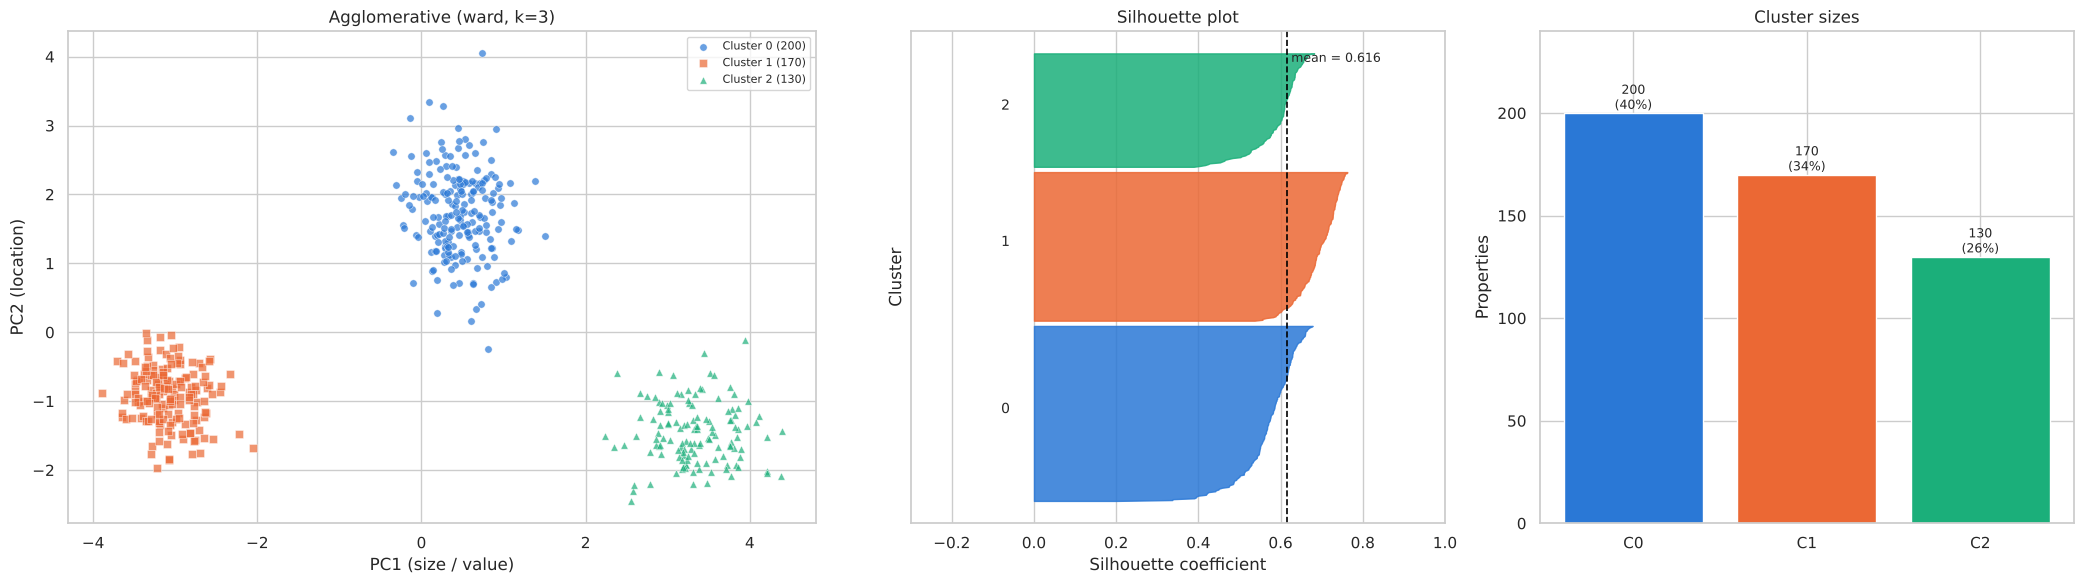

In [26]:
agg = AgglomerativeClustering(n_clusters=AGG_K, linkage=AGG_LINKAGE)
agg_labels = agg.fit_predict(X_scaled)

agg_scores = evaluate(X_scaled, agg_labels, ignore_noise=False)
print(f"Tuned Agglomerative ({AGG_LINKAGE}, k={AGG_K})")
for name, v in agg_scores.items():
    print(f"  {name:<18}: {v:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(21, 6), gridspec_kw={'width_ratios': [1.4, 1, 1]})
plot_clusters_2d(agg_labels, f'Agglomerative ({AGG_LINKAGE}, k={AGG_K})', ax=axes[0])
plot_silhouette(X_scaled, agg_labels, 'Silhouette plot', ax=axes[1])
plot_cluster_sizes(agg_labels, 'Cluster sizes', ax=axes[2])
plt.tight_layout(); plt.show()

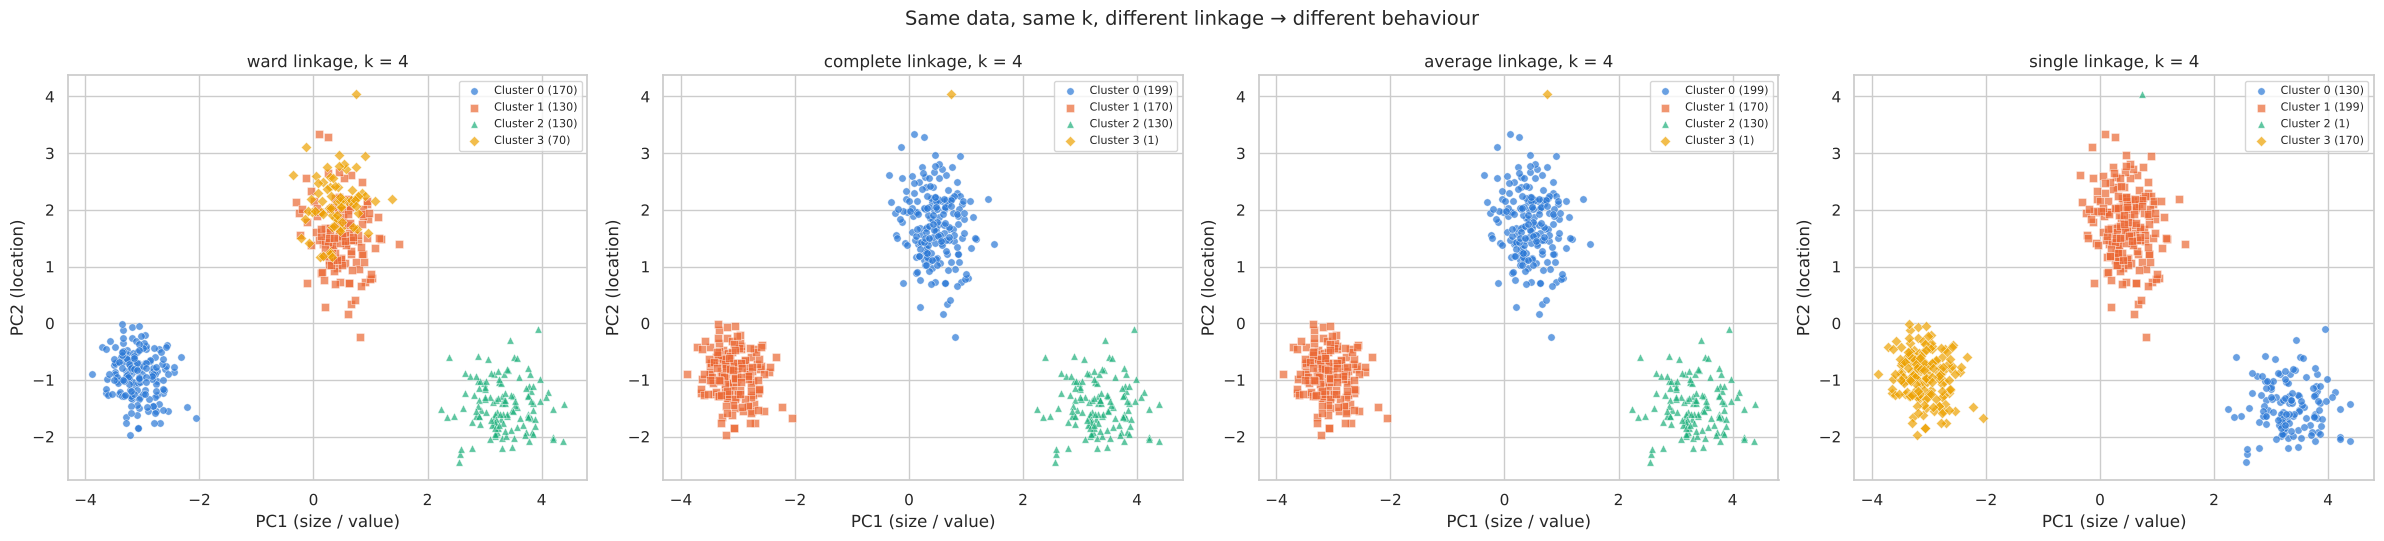

In [27]:
# How do the four linkages behave when we ask for ONE cluster too many (k = 4)?
fig, axes = plt.subplots(1, 4, figsize=(24, 5.5))
for ax, link in zip(axes, linkages):
    lab = AgglomerativeClustering(n_clusters=4, linkage=link).fit_predict(X_scaled)
    plot_clusters_2d(lab, f'{link} linkage, k = 4', ax=ax)
plt.suptitle('Same data, same k, different linkage → different behaviour', fontsize=14)
plt.tight_layout(); plt.show()

With *k* = 4, `ward` splits a real group into two halves, while `single`/`average` keep the three groups intact and put a **single unusual property** in its own "cluster". Neither is a meaningful 4th segment – which again confirms *k* = 3.

# 7. DBSCAN (Density-Based Clustering)
**How it works:** a point is a **core point** if it has at least `min_samples` neighbours within radius `eps`. Clusters grow by linking nearby core points. Points that are not reachable from any dense region become **noise (label −1)**.

* ✅ No need to choose *k*, finds any shape, detects outliers.
* ❌ Needs well-chosen `eps` and `min_samples`; struggles when densities vary or there are no gaps.

**Tuning recipe**
1. Rule of thumb: `min_samples ≈ 2 × number of features` = 20 here.
2. Use a **k-distance plot** to find a sensible `eps` range.
3. **Grid search** `eps` × `min_samples` and look for a **stable** result with little noise.

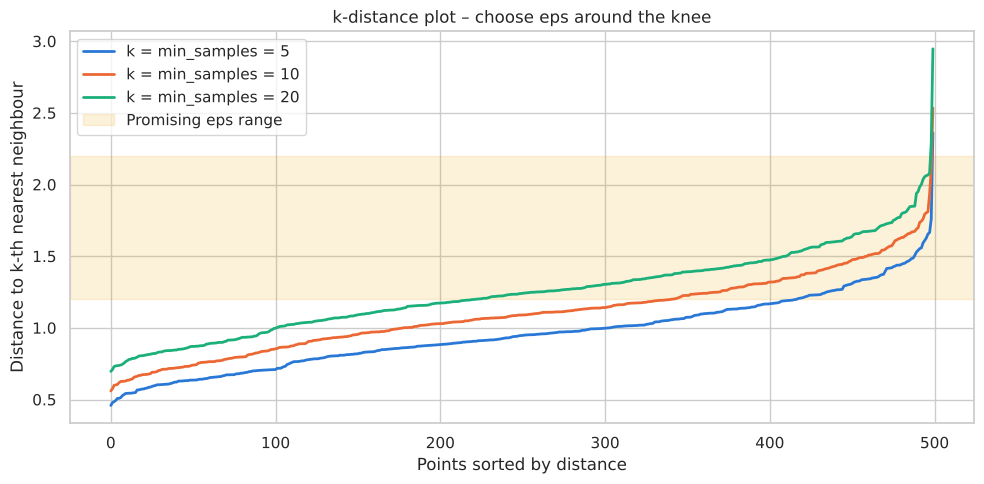

In [28]:
# k-distance plot: distance from each point to its k-th nearest neighbour, sorted.
# Points left of the "knee" are inside dense regions; the sharp rise = sparse/outlying points.
fig, ax = plt.subplots(figsize=(10, 5))
for i, k in enumerate([5, 10, 20]):
    nn = NearestNeighbors(n_neighbors=k).fit(X_scaled)
    dist, _ = nn.kneighbors(X_scaled)
    ax.plot(np.sort(dist[:, -1]), lw=2, color=CLUSTER_COLORS[i], label=f'k = min_samples = {k}')
ax.axhspan(1.2, 2.2, color=CLUSTER_COLORS[3], alpha=0.15, label='Promising eps range')
ax.set_xlabel('Points sorted by distance'); ax.set_ylabel('Distance to k-th nearest neighbour')
ax.set_title('k-distance plot – choose eps around the knee')
ax.legend(); plt.tight_layout(); plt.show()

In [29]:
# Grid search on the full 10-D scaled data (it works well here because groups are well separated)
eps_values = np.round(np.arange(0.8, 3.01, 0.1), 2)
min_samples_values = [5, 10, 15, 20, 30]
db_results = []

for eps in eps_values:
    for ms in min_samples_values:
        labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
        core = labels[labels != -1]
        n_clusters = len(set(core))
        sil = silhouette_score(X_scaled[labels != -1], core) if n_clusters >= 2 else np.nan
        db_results.append(dict(eps=eps, min_samples=ms, n_clusters=n_clusters,
                               noise_frac=np.mean(labels == -1),
                               smallest_cluster=(np.bincount(core).min() / len(labels)) if n_clusters else 0,
                               silhouette=sil))
db_results = pd.DataFrame(db_results)
print(f"Tested {len(db_results)} configurations")

Tested 115 configurations


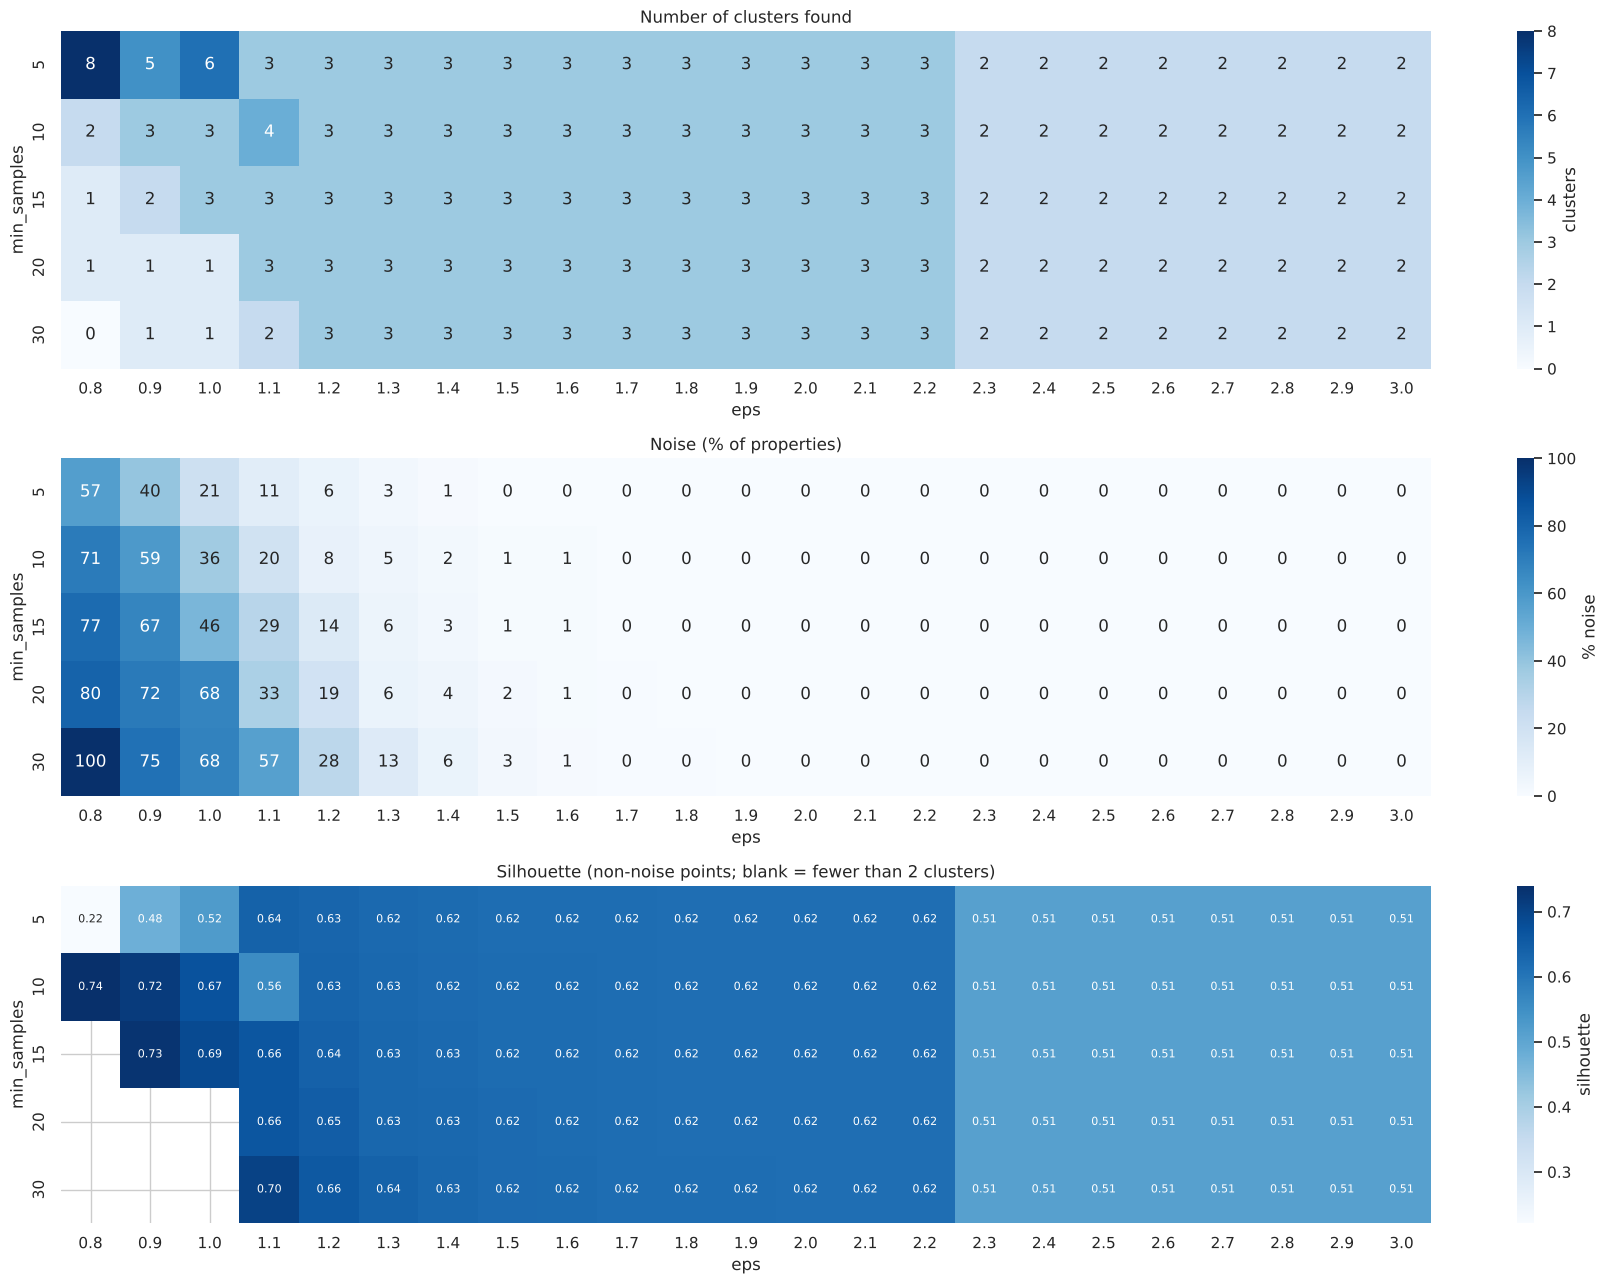

In [30]:
fig, axes = plt.subplots(3, 1, figsize=(18, 13))
n_pivot = db_results.pivot(index='min_samples', columns='eps', values='n_clusters')
noise_pivot = db_results.pivot(index='min_samples', columns='eps', values='noise_frac') * 100
sil_pivot_db = db_results.pivot(index='min_samples', columns='eps', values='silhouette')

sns.heatmap(n_pivot, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar_kws={'label': 'clusters'})
axes[0].set_title('Number of clusters found')
sns.heatmap(noise_pivot, annot=True, fmt='.0f', cmap='Blues', ax=axes[1], cbar_kws={'label': '% noise'})
axes[1].set_title('Noise (% of properties)')
sns.heatmap(sil_pivot_db, annot=True, fmt='.2f', cmap='Blues', ax=axes[2], cbar_kws={'label': 'silhouette'},
            annot_kws={'size': 8})
axes[2].set_title('Silhouette (non-noise points; blank = fewer than 2 clusters)')
plt.tight_layout(); plt.show()

**How to read these heatmaps:**
* **eps too small** (left): most points are noise and the groups shatter into fragments.
* **eps too large** (right, ≥ ~2.4): two of the groups get connected → only 2 clusters.
* **In between** there is a wide **plateau** where DBSCAN consistently finds **3 clusters with almost no noise**. A result that stays the same over a wide range of settings is a *stable*, trustworthy result.

⚠️ Watch for the silhouette trap: at small `eps` some silhouettes look high, but only because lots of points were discarded as noise (silhouette ignores noise).

**Selection rule:** at least 2 clusters, each ≥ 5% of properties, at most 5% noise → best silhouette. Among ties, prefer the **smallest eps**, so DBSCAN can still flag genuinely isolated properties.

In [31]:
MAX_NOISE = 0.05
candidates = db_results[(db_results['n_clusters'] >= 2) &
                        (db_results['smallest_cluster'] >= 0.05) &
                        (db_results['noise_frac'] <= MAX_NOISE)]
candidates = candidates.sort_values(['silhouette', 'eps'], ascending=[False, True])
display(candidates.head(8).round(3))

BEST_EPS, BEST_MS = float(candidates.iloc[0]['eps']), int(candidates.iloc[0]['min_samples'])
print(f"Chosen: eps = {BEST_EPS}, min_samples = {BEST_MS}")

,eps,min_samples,n_clusters,noise_frac,smallest_cluster,silhouette
26,1.3,10,3,0.046,0.230,0.628
33,1.4,20,3,0.044,0.232,0.627
32,1.4,15,3,0.032,0.240,0.625
25,1.3,5,3,0.032,0.238,0.625
39,1.5,30,3,0.028,0.246,0.624
31,1.4,10,3,0.024,0.242,0.624
38,1.5,20,3,0.020,0.250,0.623
30,1.4,5,3,0.014,0.250,0.621


Chosen: eps = 1.3, min_samples = 10


Tuned DBSCAN (eps=1.3, min_samples=10)
  clusters           : 3
  noise points       : 23 (4.6%)
  silhouette        : 0.6276   (non-noise points)
  davies_bouldin    : 0.5797   (non-noise points)
  calinski_harabasz : 1220.4858   (non-noise points)


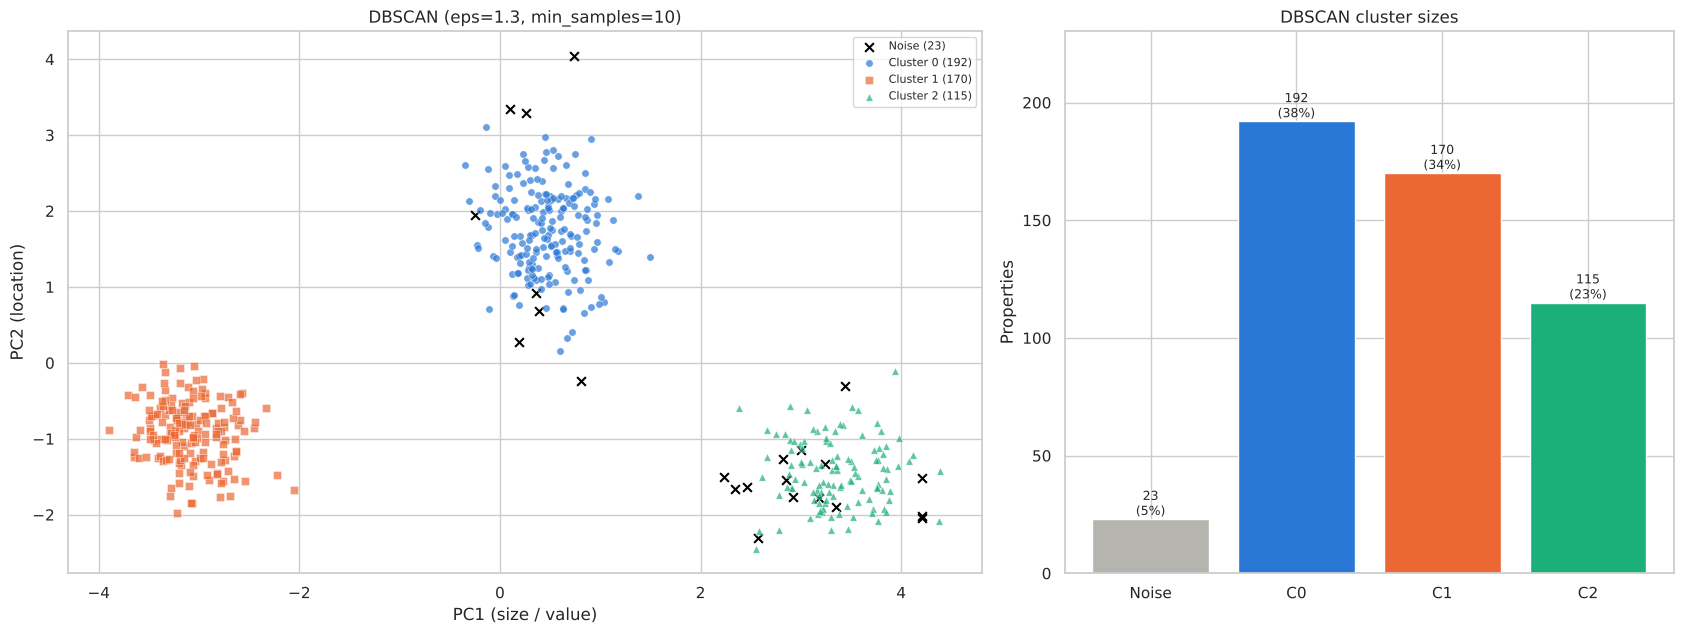

In [32]:
dbscan = DBSCAN(eps=BEST_EPS, min_samples=BEST_MS)
dbscan_labels = dbscan.fit_predict(X_scaled)

n_clusters_db = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise_db = int(np.sum(dbscan_labels == -1))
db_scores = evaluate(X_scaled, dbscan_labels, ignore_noise=True)

print(f"Tuned DBSCAN (eps={BEST_EPS}, min_samples={BEST_MS})")
print(f"  clusters           : {n_clusters_db}")
print(f"  noise points       : {n_noise_db} ({n_noise_db / len(dbscan_labels):.1%})")
for name, v in db_scores.items():
    print(f"  {name:<18}: {v:.4f}   (non-noise points)")

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={'width_ratios': [1.5, 1]})
plot_clusters_2d(dbscan_labels, f'DBSCAN (eps={BEST_EPS}, min_samples={BEST_MS})', ax=axes[0])
plot_cluster_sizes(dbscan_labels, 'DBSCAN cluster sizes', ax=axes[1])
plt.tight_layout(); plt.show()

In [33]:
# Which properties did DBSCAN flag as noise? Compare them with the median property.
if n_noise_db > 0:
    noise_rows = X_original[dbscan_labels == -1].copy()
    noise_rows.loc['median of all'] = X_original.median()
    display(noise_rows.round(1))
else:
    print("No noise points with these settings.")

,area_sqft,bedrooms,bathrooms,dist_to_city_center_km,dist_to_transit_m,school_rating,property_age_years,amenities_score,days_on_market,selling_price
15,4444.0,4.0,3.5,5.5,228.0,9.2,9.0,87.0,37.0,1476800.0
42,4452.0,6.0,4.0,5.6,325.0,9.2,4.0,92.0,22.0,1527500.0
63,4566.0,5.0,4.0,6.1,223.0,10.0,12.0,93.0,45.0,1359600.0
216,3750.0,4.0,5.0,5.1,109.0,8.3,5.0,97.0,48.0,1288100.0
227,4321.0,6.0,5.0,1.5,433.0,8.7,7.0,98.0,32.0,1351400.0
234,1805.0,3.0,2.0,10.5,1287.0,7.0,18.0,71.0,29.0,662600.0
276,4166.0,5.0,5.0,9.2,710.0,9.2,12.0,89.0,47.0,1504400.0
296,2543.0,4.0,2.0,21.4,726.0,8.4,5.0,73.0,16.0,567200.0
297,3856.0,5.0,5.0,10.6,473.0,9.7,4.0,86.0,76.0,1782100.0
299,3734.0,5.0,5.0,2.3,405.0,8.4,8.0,94.0,21.0,1439900.0


**What are these noise points?** Look at the K-Means vs DBSCAN cross-tab in Section 8: most of them belong to the **luxury** group. They are not errors – they sit on the **edge of a group that is more spread out** (luxury homes vary a lot more in size and price than small apartments).

This is a key DBSCAN limitation: it uses **one density threshold (`eps`) for the whole dataset**, so the edges of sparser clusters get labelled noise first. If you raise `eps` to ~1.7–2.2 (the plateau), the noise disappears and DBSCAN gives exactly the same 3 groups as K-Means. Our selection rule deliberately keeps a small `eps` so you can see this behaviour – try changing `BEST_EPS` yourself.

# 8. Comparing the Three Algorithms

In [34]:
comparison = pd.DataFrame({
    'K-Means':                        {**km_scores,  'n_clusters': BEST_K,        'noise_%': 0.0},
    f'Agglomerative ({AGG_LINKAGE})': {**agg_scores, 'n_clusters': AGG_K,         'noise_%': 0.0},
    'DBSCAN':                         {**db_scores,  'n_clusters': n_clusters_db,
                                       'noise_%': 100 * n_noise_db / len(dbscan_labels)},
}).T[['n_clusters', 'noise_%', 'silhouette', 'davies_bouldin', 'calinski_harabasz']]

(comparison.style
     .format({'n_clusters': '{:.0f}', 'noise_%': '{:.1f}', 'silhouette': '{:.3f}',
              'davies_bouldin': '{:.3f}', 'calinski_harabasz': '{:.0f}'})
     .highlight_max(subset=['silhouette', 'calinski_harabasz'], color='#cfe3f7')
     .highlight_min(subset=['davies_bouldin'], color='#cfe3f7'))

,n_clusters,noise_%,silhouette,davies_bouldin,calinski_harabasz
K-Means,3,0.0,0.616,0.603,1178
Agglomerative (ward),3,0.0,0.616,0.603,1178
DBSCAN,3,4.6,0.628,0.580,1220


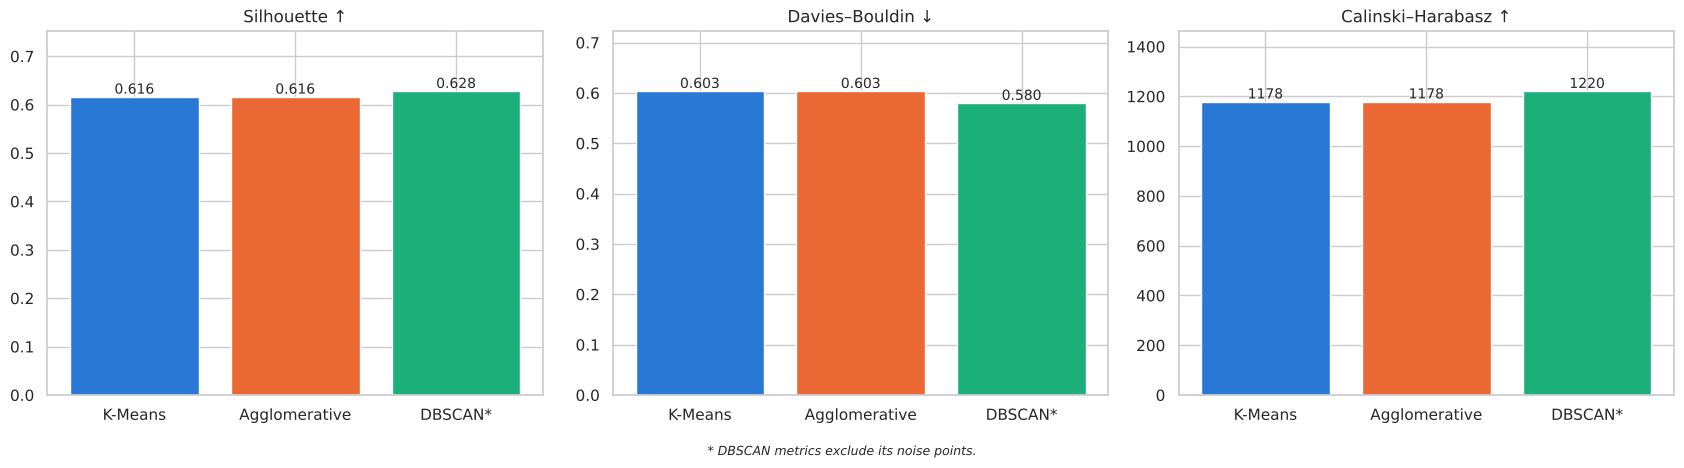

In [35]:
# One bar chart per metric (they have very different scales)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
names = ['K-Means', 'Agglomerative', 'DBSCAN*']
for ax, (col, title) in zip(axes, [('silhouette', 'Silhouette ↑'),
                                   ('davies_bouldin', 'Davies–Bouldin ↓'),
                                   ('calinski_harabasz', 'Calinski–Harabasz ↑')]):
    vals = comparison[col].values
    bars = ax.bar(names, vals, color=CLUSTER_COLORS[:3])
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v, f'{v:.3f}' if v < 100 else f'{v:.0f}',
                ha='center', va='bottom', fontsize=10)
    ax.set_title(title); ax.set_ylim(0, vals.max() * 1.2)
fig.text(0.5, -0.03, '* DBSCAN metrics exclude its noise points.', ha='center', fontsize=9, style='italic')
plt.tight_layout(); plt.show()

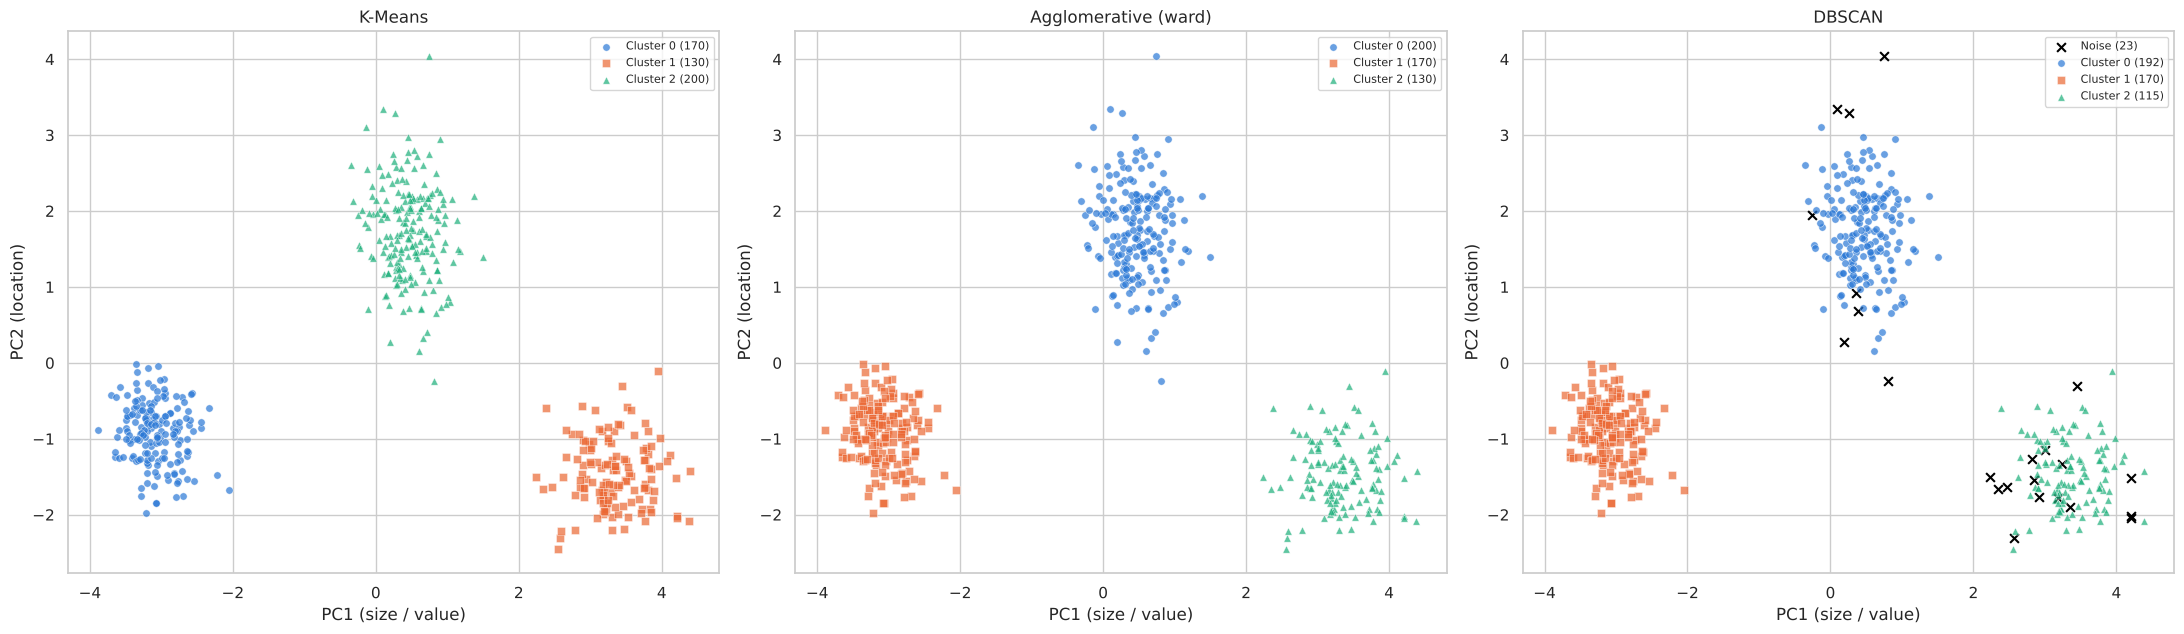

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(22, 6.5))
plot_clusters_2d(kmeans_labels, 'K-Means', ax=axes[0])
plot_clusters_2d(agg_labels, f'Agglomerative ({AGG_LINKAGE})', ax=axes[1])
plot_clusters_2d(dbscan_labels, 'DBSCAN', ax=axes[2])
plt.tight_layout(); plt.show()

⚠️ **Cluster numbers are arbitrary.** "Cluster 0" in K-Means may be "Cluster 2" in Agglomerative – the colours can differ even when the groups are identical. That's why we compare with the **Adjusted Rand Index (ARI)**, which ignores label names.

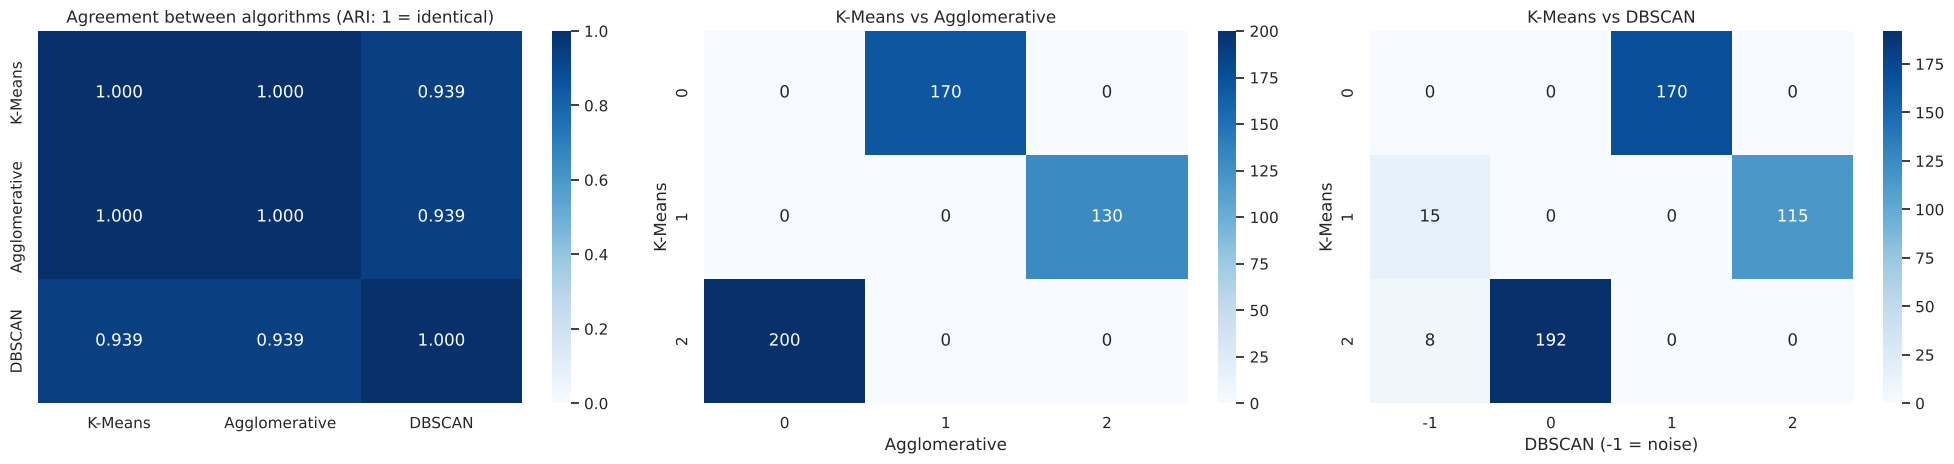

In [37]:
all_labels = {'K-Means': kmeans_labels, 'Agglomerative': agg_labels, 'DBSCAN': dbscan_labels}
ari = pd.DataFrame([[adjusted_rand_score(all_labels[a], all_labels[b]) for b in all_labels]
                    for a in all_labels], index=all_labels, columns=all_labels)

fig, axes = plt.subplots(1, 3, figsize=(20, 4.8))
sns.heatmap(ari, annot=True, fmt='.3f', cmap='Blues', vmin=0, vmax=1, ax=axes[0])
axes[0].set_title('Agreement between algorithms (ARI: 1 = identical)')
sns.heatmap(pd.crosstab(pd.Series(kmeans_labels, name='K-Means'),
                        pd.Series(agg_labels, name='Agglomerative')),
            annot=True, fmt='d', cmap='Blues', ax=axes[1])
axes[1].set_title('K-Means vs Agglomerative')
sns.heatmap(pd.crosstab(pd.Series(kmeans_labels, name='K-Means'),
                        pd.Series(dbscan_labels, name='DBSCAN (-1 = noise)')),
            annot=True, fmt='d', cmap='Blues', ax=axes[2])
axes[2].set_title('K-Means vs DBSCAN')
plt.tight_layout(); plt.show()

### Verdict
* **K-Means and Agglomerative (Ward) produce identical clusters** (ARI = 1.00) – every property gets the same group.
* **DBSCAN** finds the same 3 groups (ARI ≈ 0.94); the only difference is the ~5% of points it labels as noise. Its slightly higher scores come from leaving out those edge points – not a fair win.
* When very different algorithms – centroid-based, hierarchical and density-based – all agree, that is strong evidence the 3 segments are **real structure**, not an artefact of one method.

**Final model:** K-Means (k = 3) – simplest, fastest, assigns every property, and it can classify **new** listings with `kmeans.predict()` (Agglomerative and DBSCAN can't predict new points directly).

# 9. Cluster Profiling – What Is Each Segment?
We describe the K-Means clusters using the **original units** (sq ft, km, $), which is what a business audience understands.

In [38]:
df_final = X_original.copy()
df_final['Cluster'] = kmeans_labels
df_final['price_per_sqft'] = df_final['selling_price'] / df_final['area_sqft']   # derived, for interpretation only

profile = df_final.groupby('Cluster').mean().T
profile['Overall'] = df_final.drop(columns='Cluster').mean()
profile['Size'] = np.nan
profile.loc['count'] = list(df_final['Cluster'].value_counts().sort_index()) + [len(df_final), np.nan]
profile.drop(columns='Size').round(1)

Cluster,0,1,2,Overall
area_sqft,645.1,4316.8,2219.5,2229.5
bedrooms,1.6,4.9,3.5,3.2
bathrooms,1.2,4.1,2.4,2.4
dist_to_city_center_km,3.3,7.6,18.2,10.4
dist_to_transit_m,179.7,444.2,850.2,516.7
school_rating,5.6,9.1,8.6,7.7
property_age_years,10.4,5.6,15.6,11.2
amenities_score,45.7,91.6,67.3,66.3
days_on_market,22.2,62.0,38.5,39.1
selling_price,231304.7,1399204.6,580677.0,674707.6


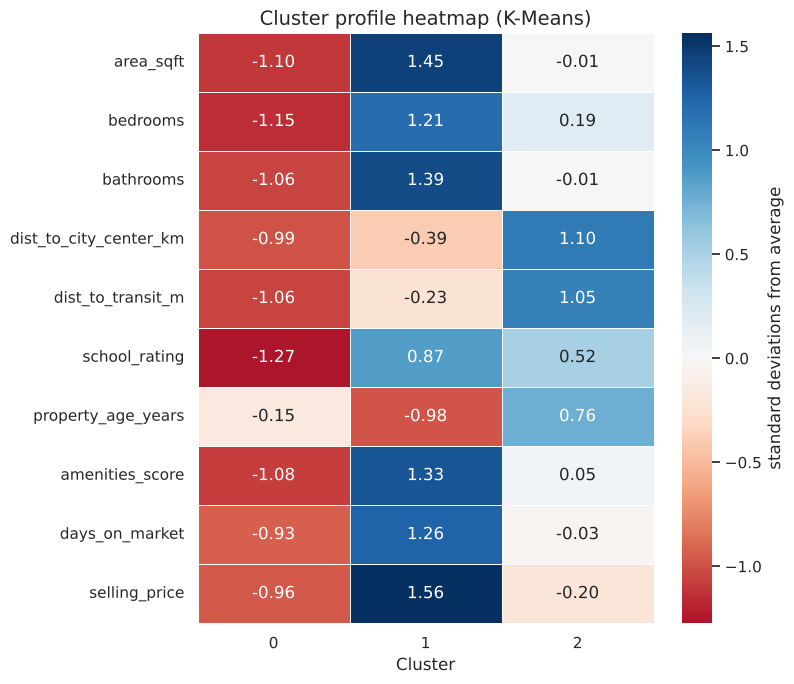

In [39]:
# Heatmap of cluster means as z-scores: blue = above average, red = below average
cluster_means_scaled = pd.DataFrame(X_scaled, columns=X.columns).groupby(kmeans_labels).mean().T
plt.figure(figsize=(8, 7))
sns.heatmap(cluster_means_scaled, cmap='RdBu', center=0, annot=True, fmt='.2f', linewidths=0.5,
            cbar_kws={'label': 'standard deviations from average'})
plt.title('Cluster profile heatmap (K-Means)', fontsize=14); plt.xlabel('Cluster')
plt.tight_layout(); plt.show()

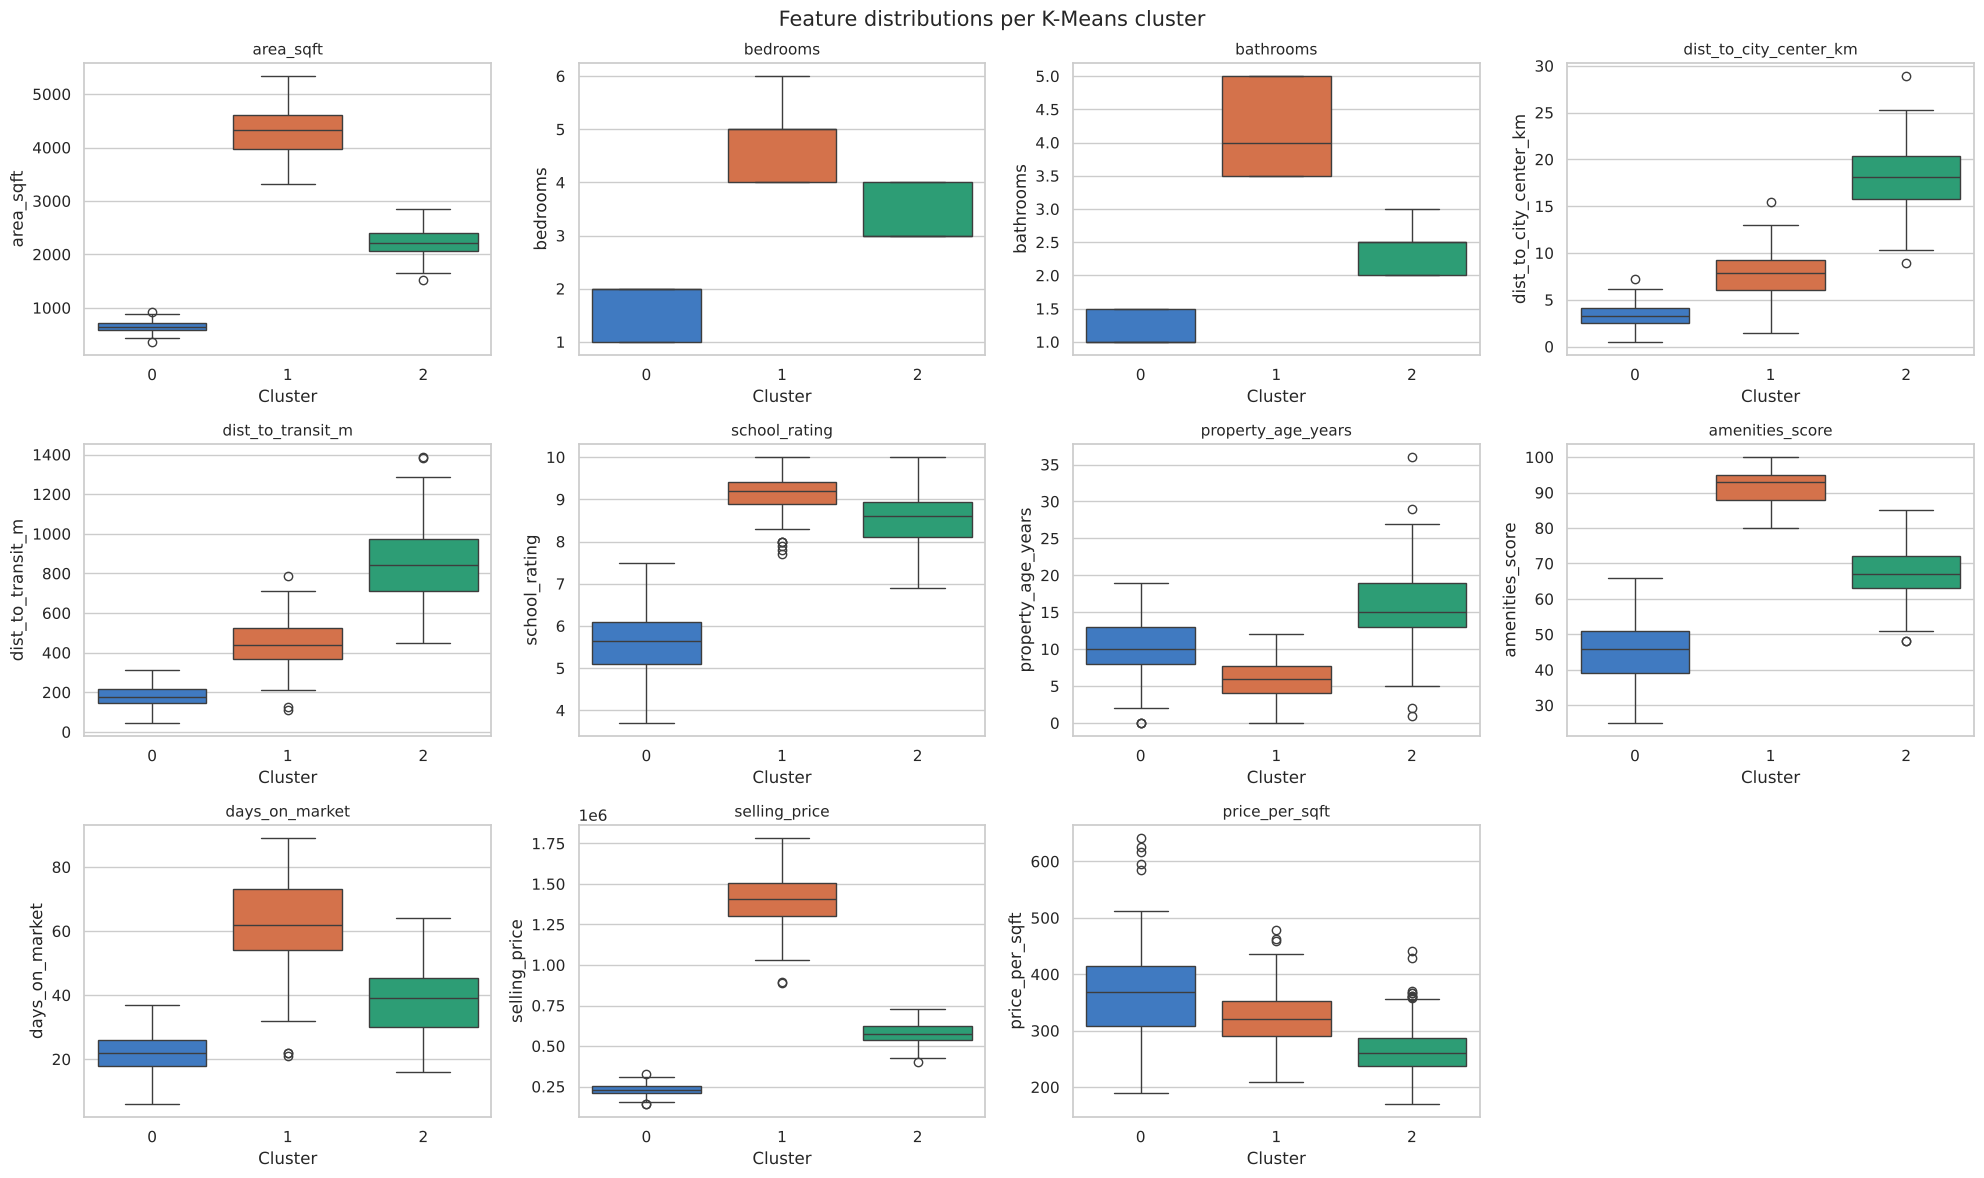

In [40]:
# Box plots of every feature per cluster
palette = {i: CLUSTER_COLORS[i] for i in range(BEST_K)}
plot_cols = list(X.columns) + ['price_per_sqft']
fig, axes = plt.subplots(3, 4, figsize=(20, 12))
for ax, col in zip(axes.flat, plot_cols):
    sns.boxplot(data=df_final, x='Cluster', y=col, hue='Cluster', palette=palette, ax=ax, legend=False)
    ax.set_title(col, fontsize=11); ax.set_xlabel('Cluster')
axes.flat[-1].set_visible(False)
plt.suptitle('Feature distributions per K-Means cluster', fontsize=15)
plt.tight_layout(); plt.show()

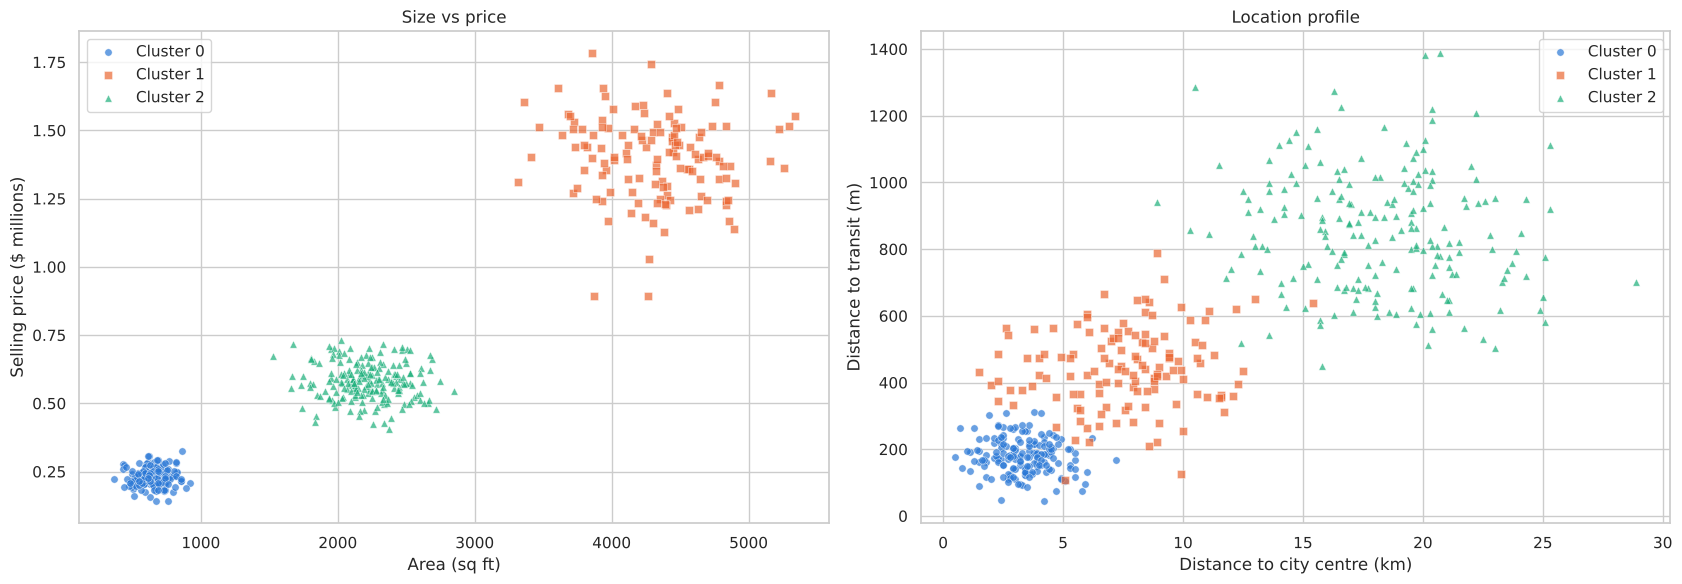

In [41]:
# Two "business" scatter plots in real units
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
for lab in range(BEST_K):
    m = df_final['Cluster'] == lab
    axes[0].scatter(df_final.loc[m, 'area_sqft'], df_final.loc[m, 'selling_price'] / 1e6, s=28, alpha=0.7,
                    c=CLUSTER_COLORS[lab], marker=MARKERS[lab], edgecolors='white', linewidths=0.4,
                    label=f'Cluster {lab}')
    axes[1].scatter(df_final.loc[m, 'dist_to_city_center_km'], df_final.loc[m, 'dist_to_transit_m'], s=28,
                    alpha=0.7, c=CLUSTER_COLORS[lab], marker=MARKERS[lab], edgecolors='white',
                    linewidths=0.4, label=f'Cluster {lab}')
axes[0].set_xlabel('Area (sq ft)'); axes[0].set_ylabel('Selling price ($ millions)')
axes[0].set_title('Size vs price')
axes[1].set_xlabel('Distance to city centre (km)'); axes[1].set_ylabel('Distance to transit (m)')
axes[1].set_title('Location profile')
for ax in axes:
    ax.legend()
plt.tight_layout(); plt.show()

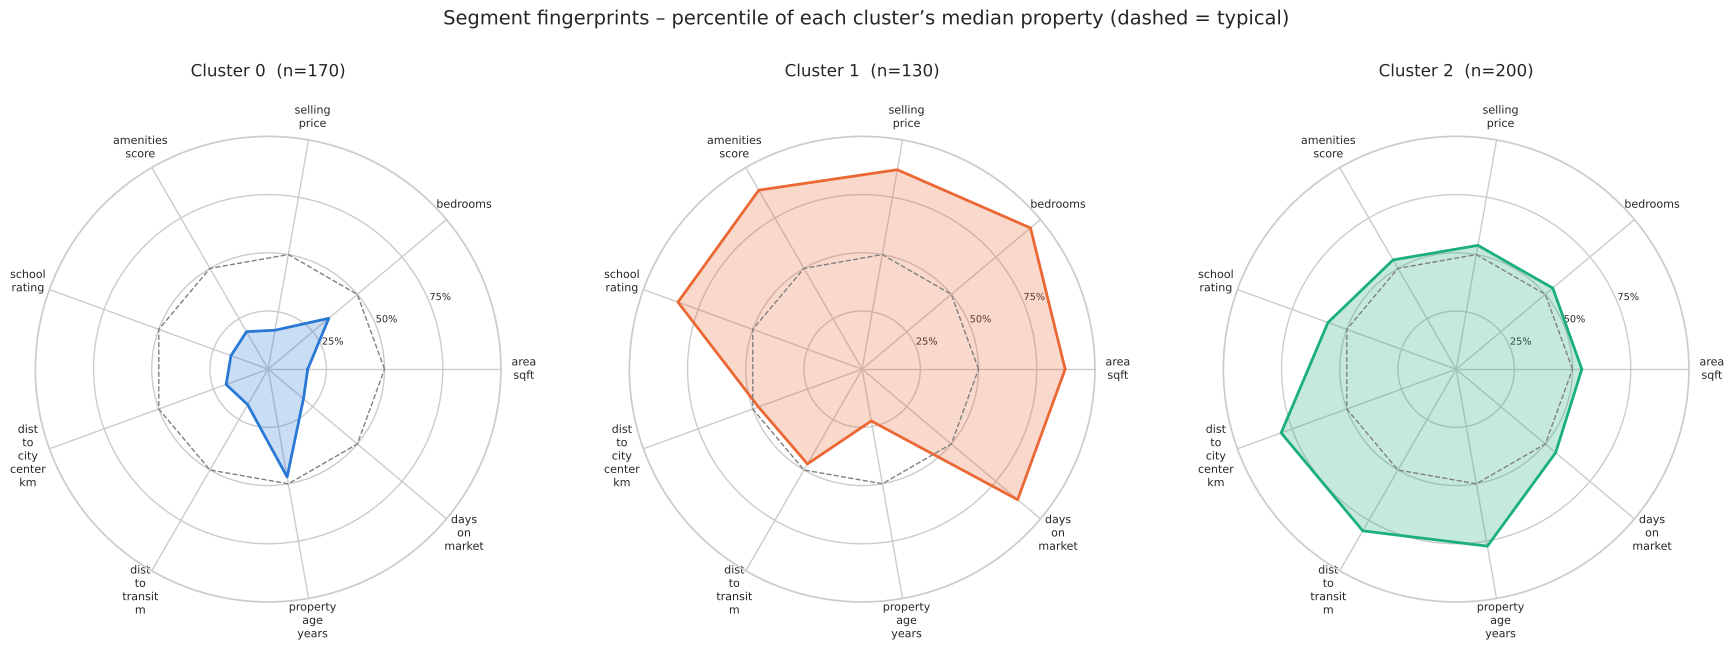

In [42]:
# Radar chart: percentile of each cluster's median property among ALL properties
# (0.5 = a typical property; 0.9 = higher than 90% of properties)
radar_features = ['area_sqft', 'bedrooms', 'selling_price', 'amenities_score', 'school_rating',
                  'dist_to_city_center_km', 'dist_to_transit_m', 'property_age_years', 'days_on_market']
med = df_final.groupby('Cluster')[radar_features].median()
pct = med.apply(lambda col: col.map(lambda v: (X_original[col.name] <= v).mean()))

angles = np.linspace(0, 2 * np.pi, len(radar_features), endpoint=False).tolist()
angles += angles[:1]
fig, axes = plt.subplots(1, BEST_K, figsize=(6 * BEST_K, 6), subplot_kw=dict(polar=True))
for c, ax in zip(pct.index, np.atleast_1d(axes)):
    vals = pct.loc[c].tolist(); vals += vals[:1]
    ax.plot(angles, vals, color=CLUSTER_COLORS[c], lw=2)
    ax.fill(angles, vals, color=CLUSTER_COLORS[c], alpha=0.25)
    ax.plot(angles, [0.5] * len(angles), color='grey', ls='--', lw=1)   # dashed ring = typical property
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels([f.replace('_', '\n') for f in radar_features], fontsize=8)
    ax.set_yticks([0.25, 0.5, 0.75]); ax.set_yticklabels(['25%', '50%', '75%'], fontsize=7)
    ax.set_ylim(0, 1)
    ax.set_title(f'Cluster {c}  (n={np.sum(kmeans_labels == c)})', pad=20)
plt.suptitle('Segment fingerprints – percentile of each cluster’s median property (dashed = typical)',
             fontsize=14, y=1.04)
plt.tight_layout(); plt.show()

In [43]:
# Median table in real units - the numbers you would put in a report
summary = df_final.groupby('Cluster').median().round(1)
summary['properties'] = df_final['Cluster'].value_counts().sort_index()
summary

,area_sqft,bedrooms,bathrooms,dist_to_city_center_km,dist_to_transit_m,school_rating,property_age_years,amenities_score,days_on_market,selling_price,price_per_sqft,properties
Cluster,,,,,,,,,,,,
0,648.0,2.0,1.0,3.3,178.0,5.6,10.0,46.0,22.0,229650.0,368.2,170
1,4333.0,5.0,4.0,7.9,438.0,9.2,6.0,93.0,62.0,1404800.0,321.0,130
2,2218.5,3.0,2.5,18.2,842.0,8.6,15.0,67.0,39.0,576200.0,261.3,200


### 🏠 Market segments (K-Means, k = 3)
*(Averages from the profile table above. Cluster numbers stay the same as long as `random_state=42` is unchanged.)*

| Cluster | Segment | Share | Profile | Who buys / how to sell |
|---|---|---|---|---|
| **0** | 🏙️ **Urban compact apartments** | 34% | ~650 sq ft, 1–2 bedrooms, ~3 km from the centre and ~180 m from transit; weaker schools (5.6) and fewer amenities; ~\$230k; **highest price per sq ft (~\$368)**; sells fastest (~22 days) | First-time buyers, young professionals, rental investors – market on location and commute |
| **1** | 💎 **Luxury homes** | 26% | ~4,300 sq ft, ~5 bedrooms / 4 bathrooms, newest (~6 yrs), top schools (9.1) and amenities (92), ~7.6 km out; ~\$1.4M; **slowest to sell (~62 days)** | Affluent families – premium staging, longer marketing campaigns, price carefully |
| **2** | 🏡 **Suburban family homes** | 40% | ~2,200 sq ft, 3–4 bedrooms, ~18 km from the centre and ~850 m from transit; good schools (8.6); oldest (~16 yrs); ~\$580k; **lowest price per sq ft (~\$265)** | Families who want space and schools for the money – highlight value and school catchment |

💡 Notice the **trade-off**: you pay the most per square foot for location (urban), and the least for distance (suburban).

In [44]:
df_out = df.copy()
df_out['KMeans_Cluster'] = kmeans_labels
df_out['Agg_Cluster'] = agg_labels
df_out['DBSCAN_Cluster'] = dbscan_labels    # -1 = unusual listing
df_out.to_csv('real_estate_with_clusters.csv', index=False)
print("Saved real_estate_with_clusters.csv")
df_out.head()

Saved real_estate_with_clusters.csv


,area_sqft,bedrooms,bathrooms,dist_to_city_center_km,dist_to_transit_m,school_rating,property_age_years,amenities_score,days_on_market,selling_price,KMeans_Cluster,Agg_Cluster,DBSCAN_Cluster
0,2424,4,2.5,21.8,928,8.3,10,71,53,598800,2,0,0
1,822,1,1.5,5.8,76,6.0,11,56,11,247500,0,1,1
2,4249,5,3.5,3.7,391,9.6,3,97,61,1439400,1,2,2
3,571,1,1.5,6.2,233,4.9,10,38,19,206000,0,1,1
4,632,2,1.5,3.4,145,4.4,14,39,35,203700,0,1,1


# 10. Summary & Key Lessons

| Algorithm | Tuning done | Result |
|---|---|---|
| K-Means | k = 2–10 with elbow, silhouette, DB, CH; `n_init=50` | **k = 3**, silhouette ≈ 0.62 |
| Agglomerative | 4 linkages × k = 2–8, dendrogram, merge-distance plot, min-cluster-size rule | **Ward, k = 3** – identical to K-Means |
| DBSCAN | k-distance plot + 115-configuration grid of `eps` × `min_samples` | **3 clusters**, ~5% noise (edge of the luxury group) |

### Key lessons
1. **Look before you cluster.** Multimodal histograms and visible clouds in the pair plot hinted at 3 groups before any algorithm ran.
2. **Check, don't assume.** No missing values and low skew meant no imputation or log transform was needed – but **scaling is always required** for distance-based methods.
3. **Clear structure = agreement.** When groups are well separated, all metrics point to the same *k*, all linkages agree, and DBSCAN shows a wide stable plateau. If methods disagree a lot, the structure is weak.
4. **Always check cluster sizes**, not just scores – `single`/`average` linkage can "win" by isolating one outlier.
5. **DBSCAN uses one density for everything**, so sparser clusters lose their edge points to noise.
6. This dataset is unusually clean (it looks designed for practice). Real-world data is usually messier, with lower silhouette scores and less agreement between methods.

### 🧪 Try it yourself
1. `selling_price` and `days_on_market` are **outcomes** of a sale, not features of the property. Drop them, re-run, and check whether the 3 segments change.
2. Remove the scaling step (`X_scaled = X.values`) and re-run K-Means. Which feature takes over, and why?
3. Replace `StandardScaler` with `MinMaxScaler`. Do the clusters change?
4. Set `BEST_EPS = 1.8` for DBSCAN. What happens to the noise points?
5. Use `kmeans.predict()` to classify a new listing: 1,200 sq ft, 2 bed, 1.5 bath, 6 km from centre, 300 m to transit, school 7.0, 8 years old, amenities 60, 30 days, \$400,000. (Hint: scale it with `scaler.transform` first.)